# Etapa 3 – Investigação dos dados e consultas SQL

As seções estão agrupadas por tema. Cada consulta SQL vem seguida de uma interpretação, e a seção 14 reúne as principais descobertas.

| Tema | Seções |
|---|---|
| Dados | 1. Configuração · 2. Visões de apoio · 3. Cuidados com os dados |
| Comportamento temporal | 4. Evolução anual · 5. Sazonalidade mensal · 6. Hora do pico · 7. Granularidades |
| Calendário | 8. Teste de H2 – feriados |
| Clima | 9. Carga por faixa de Tmax · 10. Teste de H1 – calor · 11. Teste de H3 – frio · 12. Tempestades |
| Eventos excepcionais | 13. Desvios da média móvel |
| Conclusão | 14. Principais descobertas |

## 1. Configuração

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson

pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 3)

DIR_PROC = Path("processado")

# Calendário: o que conta como "dia útil comum"
RECESSO = ("12-24", "01-06")   # recesso de fim de ano (mm-dd nas duas pontas)
EXCLUIR_PANDEMIA = False        # consulta da seção 9

# Seção 6 (hora do pico)
VERAO, INVERNO = (12, 1, 2), (6, 7, 8)   # meses de cada estação

# Seção 7 (granularidades)
FAIXA_DISPERSAO = (8, 36)   # °C, eixo x dos gráficos de dispersão

# Seção 8 (teste de H2)
MIN_CONTROLES = 2       # dias úteis comuns comparáveis exigidos para o feriado entrar no teste

# Seção 9 (faixas de Tmax)
LARGURA_FAIXA = 2.0     # °C
MIN_DIAS_FAIXA = 20     # faixas com menos dias ficam fora da tabela e do gráfico
LIMIAR_CALOR = 25.0     # limiar de H1 na proposta: referência no gráfico da seção 9 e recorte do teste da seção 10

# Seção 10 (teste de H1)
LIMIARES_H1 = [23, 24, 25, 26, 27]   # °C, sensibilidade do resultado ao limiar
HAC_LAGS = 10                        # defasagens dos erros-padrão Newey-West (cerca de duas semanas de dias úteis)

# Seção 11 (teste de H3)
CENTRO_QUAD = 20.0                    # °C, centro da Tmax no ajuste quadrático (perto do mínimo da curva da seção 9)
LIMIAR_FRIO = 20.0                    # °C, dias abaixo disso formam o ramo frio
LIMIARES_H3 = [18, 19, 20, 21, 22]    # °C, sensibilidade do ramo frio ao limiar

# Seção 12 (tempestades)
MESES_QUENTES = (10, 11, 12, 1, 2, 3)   # meses em que se concentram as tempestades de calor

# Seção 13 (desvios da média móvel)
JANELA_MM = 28                 # dias anteriores usados como referência
MM_MESMO_DIA_SEMANA = True     # True: referência = mesmos dias da semana dentro da janela (28 dias -> 4 valores)
TOP_N_DESVIOS = 30
# Regras da causa provável (13.2); a 13.5 compara as alternativas
CALOR_RELATIVO = True              # True: calor = Tmax acima da média dos 28 dias anteriores; False: Tmax >= LIMIAR_CALOR
LIMIAR_ANOMALIA = 2.0              # °C acima da média dos 28 dias anteriores
MIN_ESPECIAIS_REF = 1              # dias de feriado/recesso/ponte na referência para ela contar como rebaixada
ROTULO_COMBINADO = True            # True: calor + referência rebaixada vira uma causa própria
FIM_ADAPTACAO_PANDEMIA = "2020-05-01"   # depois disso a referência já inclui a pandemia

# Cores (paleta categórica de referência em ordem fixa)
COR = ["#2a78d6", "#eb6834", "#1baf7a"]
TINTA, TINTA_2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
DIVERGENTE = LinearSegmentedColormap.from_list("azul_vermelho", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.figsize": (12, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False,
})

con = duckdb.connect()

def sql(consulta):
    """Roda a consulta no DuckDB e devolve um DataFrame."""
    return con.sql(consulta).df()

## 2. Visões de apoio

In [2]:
con.sql(f"""
CREATE OR REPLACE VIEW diaria AS
SELECT * FROM read_parquet('{DIR_PROC / "base_diaria.parquet"}')
""")

con.sql(f"""
CREATE OR REPLACE VIEW diaria_cal AS
SELECT *,
       CASE
           WHEN fim_de_semana THEN 'fim de semana'
           WHEN feriado THEN 'feriado'
           WHEN strftime(data, '%m-%d') >= '{RECESSO[0]}'
             OR strftime(data, '%m-%d') <= '{RECESSO[1]}' THEN 'recesso'
           WHEN ponte THEN 'ponte'
           WHEN vespera_feriado THEN 'véspera'
           WHEN pos_feriado THEN 'pós-feriado'
           ELSE 'útil comum'
       END AS tipo_dia
FROM diaria
""")

sql("""
SELECT tipo_dia, COUNT(*) AS n_dias
FROM diaria_cal
GROUP BY tipo_dia
ORDER BY n_dias DESC
""")

,tipo_dia,n_dias
0,útil comum,2515
1,fim de semana,1148
2,feriado,118
3,recesso,94
4,véspera,63
5,pós-feriado,50
6,ponte,30


## 3. Cuidados com os dados

### 3.1 Tendência anual e dias quentes por ano

In [3]:
sql("""
SELECT ano,
       ROUND(AVG(carga_max) FILTER (WHERE tipo_dia = 'útil comum')) AS carga_max_media_uteis,
       COUNT(*) FILTER (WHERE tmax >= 28) AS dias_tmax_28_ou_mais,
       ROUND(AVG(tmax), 2) AS tmax_media,
       MAX(regime_ons) AS regime_ons_fim_do_ano,
       COUNT(*) FILTER (WHERE pandemia) AS dias_pandemia
FROM diaria_cal
GROUP BY ano
ORDER BY ano
""")

,ano,carga_max_media_uteis,dias_tmax_28_ou_mais,tmax_media,regime_ons_fim_do_ano,dias_pandemia
0,2015,13375.0,46,23.52,0,0
1,2016,13598.0,50,22.78,0,0
2,2017,13942.0,52,23.91,0,0
3,2018,14157.0,45,23.54,0,0
4,2019,14290.0,73,24.16,0,0
5,2020,14480.0,55,23.82,0,291
6,2021,15176.0,41,23.23,1,0
7,2022,15224.0,64,23.22,1,0
8,2023,16060.0,75,24.26,2,0
9,2024,17084.0,70,24.41,2,0


### 3.2 Carga de cada tipo de dia em relação ao dia útil comum do mesmo ano

In [4]:
sql("""
WITH ref AS (
    SELECT ano, AVG(carga_max) AS carga_ref
    FROM diaria_cal
    WHERE tipo_dia = 'útil comum' AND NOT dia_incompleto
    GROUP BY ano
)
SELECT tipo_dia,
       COUNT(*) AS n_dias,
       ROUND(AVG(d.carga_max / r.carga_ref), 3) AS carga_rel,
       ROUND(AVG(tmax), 1) AS tmax_media
FROM diaria_cal d
JOIN ref r USING (ano)
WHERE NOT dia_incompleto
GROUP BY tipo_dia
ORDER BY carga_rel
""")

,tipo_dia,n_dias,carga_rel,tmax_media
0,fim de semana,1148,0.847,23.8
1,feriado,118,0.864,24.8
2,ponte,30,0.902,23.5
3,recesso,94,0.914,28.0
4,véspera,63,0.958,22.9
5,pós-feriado,50,0.985,24.2
6,útil comum,2514,1.000,23.5


> **Interpretação**
>
> Tendência e calor andam juntos. A carga máxima média dos dias úteis comuns subiu de 13,4 GW em 2015 para 17,6 GW em 2025 (+32%). No mesmo período os dias com Tmax ≥ 28 °C passaram de 45–52 por ano (2015–2018) para 70–87 (2023–2025). Os maiores saltos de um ano para o outro ficam perto das trocas de regime do ONS: +4,8% em 2021 (troca em mar/2021, mas comparado com 2020, ano da pandemia), +5,5% em 2023 (troca em 29/04/2023) e +6,4% em 2024 (primeiro ano inteiro no regime 2), contra +0,3% a +3,2% nos outros anos. Comparar MWmed de anos diferentes atribuiria ao calor um aumento que vem do crescimento do consumo e da metodologia. Por isso as seções 5 e 9 dividem a carga pela média do próprio ano. Em 2020 a média anual não mostra a pandemia (ficou até acima de 2019), porque a queda se concentrou em poucos meses. Ela aparece no índice mensal da seção 5 (abr/2020).
>
> Os dias especiais têm carga menor, e o recesso e os feriados caem em dias quentes. Todos os tipos de dia especiais têm carga menor que o dia útil comum: fim de semana −15%, feriado −14%, ponte −10%, recesso −9%, véspera −4% e pós-feriado −1,5%. O recesso é o grupo mais quente (Tmax média de 28,0 °C, contra 23,5 °C nos dias úteis comuns), e os feriados também ficam acima da média (24,8 °C, por causa do Carnaval no verão). Se esses dias entrassem na seção 9, eles puxariam para baixo justamente as faixas mais quentes e achatariam o ramo de calor da curva. Por isso a seção 9 usa só dias úteis comuns, e a seção 5 mostra também o índice dos dias úteis.
>
> A diferença entre feriados e dias úteis (−14%) é uma primeira indicação a favor de H2, mas ainda sem controle de mês e dia da semana. O teste formal fica para a seção de hipóteses.

## 4. Evolução anual da carga máxima

**Pergunta:** como a carga máxima evoluiu ano a ano e qual foi a variação % em relação ao ano anterior? Quanto dessa variação coincide com as trocas de regime do ONS?

### 4.1 Nível e variação de um ano para o outro

In [5]:
con.sql("""
CREATE OR REPLACE VIEW carga_anual AS
SELECT ano,
       list_sort(list(DISTINCT regime_ons)) AS regimes,
       COUNT(*) AS n_dias,
       AVG(carga_max) AS media,
       AVG(carga_max) FILTER (WHERE tipo_dia = 'útil comum') AS media_uteis,
       QUANTILE_CONT(carga_max, 0.95) AS p95,
       MAX(carga_max) AS pico,
       ARG_MAX(data, carga_max) AS data_pico
FROM diaria_cal
WHERE NOT dia_incompleto
GROUP BY ano
""")

evolucao_anual = sql("""
SELECT ano, regimes, n_dias,
       ROUND(media) AS media_mw,
       ROUND(100 * (media / LAG(media) OVER w - 1), 2) AS var_media_pct,
       ROUND(media_uteis) AS media_uteis_mw,
       ROUND(100 * (media_uteis / LAG(media_uteis) OVER w - 1), 2) AS var_uteis_pct,
       ROUND(p95) AS p95_mw,
       ROUND(100 * (p95 / LAG(p95) OVER w - 1), 2) AS var_p95_pct,
       ROUND(pico) AS pico_mw,
       data_pico,
       ROUND(100 * (pico / LAG(pico) OVER w - 1), 2) AS var_pico_pct,
       len(regimes) = 1 AND regimes = LAG(regimes) OVER w AS mesmo_regime_ano_anterior
FROM carga_anual
WINDOW w AS (ORDER BY ano)
ORDER BY ano
""")
evolucao_anual

,ano,regimes,n_dias,media_mw,var_media_pct,media_uteis_mw,var_uteis_pct,p95_mw,var_p95_pct,pico_mw,data_pico,var_pico_pct,mesmo_regime_ano_anterior
0,2015,[0],364,12584.0,NaN,13375.0,NaN,15482.0,NaN,16631.0,2015-01-13,NaN,<NA>
1,2016,[0],366,12873.0,2.29,13598.0,1.67,15530.0,0.31,16369.0,2016-02-26,-1.57,True
2,2017,[0],365,13173.0,2.33,13942.0,2.53,15947.0,2.68,17506.0,2017-02-20,6.94,True
3,2018,[0],365,13368.0,1.48,14157.0,1.54,15830.0,-0.73,17305.0,2018-12-17,-1.15,True
4,2019,[0],365,13577.0,1.57,14290.0,0.94,16291.0,2.91,18652.0,2019-01-30,7.78,True
5,2020,[0],366,13775.0,1.46,14480.0,1.33,16672.0,2.34,18161.0,2020-03-13,-2.63,True
6,2021,"[0, 1]",365,14475.0,5.08,15176.0,4.81,16227.0,-2.67,17537.0,2021-01-11,-3.44,False
7,2022,[1],365,14529.0,0.37,15224.0,0.31,17036.0,4.99,18925.0,2022-01-24,7.92,False
8,2023,"[1, 2]",365,15212.0,4.70,16060.0,5.50,17570.0,3.13,20143.0,2023-12-18,6.44,False
9,2024,[2],366,16204.0,6.52,17084.0,6.37,19100.0,8.71,21613.0,2024-02-07,7.29,False


### 4.2 Variação só entre dias do mesmo regime

Nos anos de troca (2021 e 2023) e nos anos seguintes (2022 e 2024), a variação da 4.1 compara anos que estão, em parte, em regimes diferentes do ONS. Aqui cada dia é comparado com o mesmo dia do ano anterior, e o par só entra quando os dois dias estão no mesmo `regime_ons`. Como os dois lados têm os mesmos dias do calendário, a sazonalidade se cancela. Nesses anos, porém, a comparação cobre só parte do ano (`n_dias_comparados`).

In [6]:
variacao_regime = sql("""
WITH pares AS (
    SELECT a.ano, a.data, a.regime_ons, a.carga_max AS carga, b.carga_max AS carga_ano_anterior
    FROM diaria_cal a
    JOIN diaria_cal b ON b.data = a.data - INTERVAL 1 YEAR
    WHERE a.regime_ons = b.regime_ons
      AND NOT a.dia_incompleto AND NOT b.dia_incompleto
      AND strftime(a.data, '%m-%d') <> '02-29'
)
SELECT p.ano,
       list_sort(list(DISTINCT p.regime_ons)) AS regime,
       COUNT(*) AS n_dias_comparados,
       strftime(MIN(p.data), '%d/%m') || '–' || strftime(MAX(p.data), '%d/%m') AS periodo,
       ROUND(100 * (AVG(p.carga) / AVG(p.carga_ano_anterior) - 1), 2) AS var_mesmo_regime_pct,
       ROUND(100 * (ANY_VALUE(a.media) / ANY_VALUE(a.media_ant) - 1), 2) AS var_ano_inteiro_pct
FROM pares p
JOIN (SELECT ano, media, LAG(media) OVER (ORDER BY ano) AS media_ant FROM carga_anual) a USING (ano)
GROUP BY p.ano
ORDER BY p.ano
""")
variacao_regime

,ano,regime,n_dias_comparados,periodo,var_mesmo_regime_pct,var_ano_inteiro_pct
0,2016,[0],364,01/01–31/12,2.29,2.29
1,2017,[0],365,01/01–31/12,2.37,2.33
2,2018,[0],365,01/01–31/12,1.48,1.48
3,2019,[0],365,01/01–31/12,1.57,1.57
4,2020,[0],365,01/01–31/12,1.47,1.46
5,2021,[0],59,01/01–28/02,-1.21,5.08
6,2022,[1],306,01/03–31/12,-0.96,0.37
7,2023,[1],118,01/01–28/04,2.62,4.70
8,2024,[2],247,29/04–31/12,5.24,6.52
9,2025,[2],365,01/01–31/12,3.60,3.56


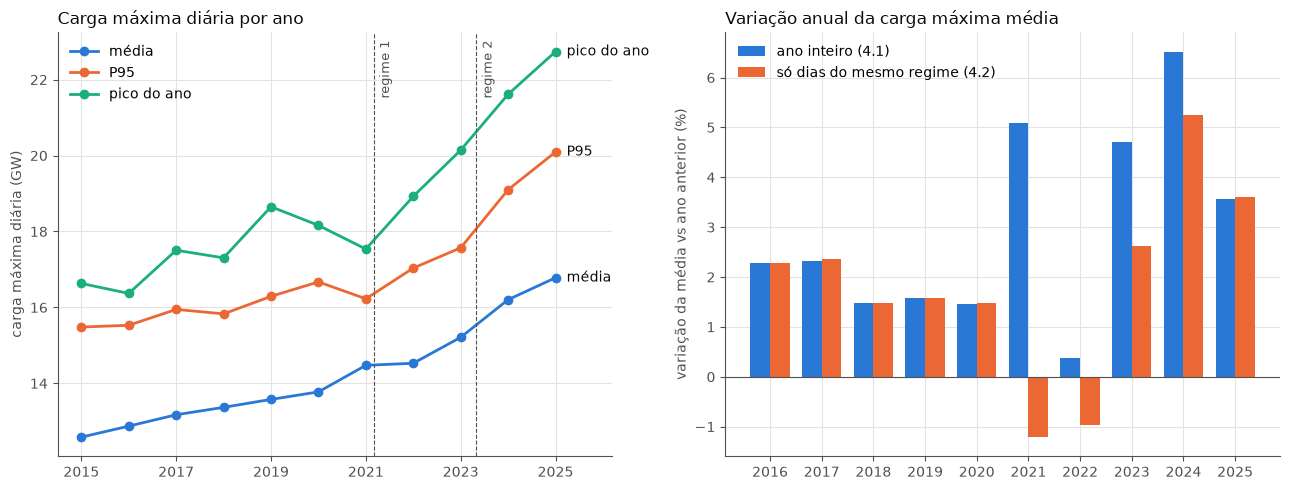

In [7]:
TROCAS_REGIME = {2021 + 59 / 365: "regime 1", 2023 + 118 / 365: "regime 2"}   # 01/03/2021 e 29/04/2023
anos = evolucao_anual["ano"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for i, (col, nome) in enumerate([("media_mw", "média"), ("p95_mw", "P95"), ("pico_mw", "pico do ano")]):
    ax1.plot(anos, evolucao_anual[col] / 1000, color=COR[i], marker="o", label=nome)
    ax1.annotate(nome, (anos.iloc[-1], evolucao_anual[col].iloc[-1] / 1000), xytext=(8, 0),
                 textcoords="offset points", va="center", color=TINTA)
for x, rotulo in TROCAS_REGIME.items():
    ax1.axvline(x, color=TINTA_2, lw=0.8, ls="--")
    ax1.annotate(rotulo, (x, 0.98), xycoords=("data", "axes fraction"), xytext=(4, 0),
                 textcoords="offset points", color=TINTA_2, fontsize=9, rotation=90, va="top")
ax1.set_ylabel("carga máxima diária (GW)")
ax1.set_title("Carga máxima diária por ano", loc="left", color=TINTA)
ax1.set_xlim(anos.min() - 0.5, anos.max() + 1.2)
ax1.set_xticks(anos[::2])
ax1.legend(loc="upper left")

largura = 0.38
v = variacao_regime
ax2.bar(v["ano"] - largura / 2, v["var_ano_inteiro_pct"], largura, color=COR[0], label="ano inteiro (4.1)")
ax2.bar(v["ano"] + largura / 2, v["var_mesmo_regime_pct"], largura, color=COR[1], label="só dias do mesmo regime (4.2)")
ax2.axhline(0, color=TINTA_2, lw=0.8)
ax2.set_xticks(v["ano"])
ax2.set_ylabel("variação da média vs ano anterior (%)")
ax2.set_title("Variação anual da carga máxima média", loc="left", color=TINTA)
ax2.legend(loc="upper left")
plt.tight_layout()

> **Interpretação**
>
> A carga máxima cresceu nas três medidas entre 2015 e 2025: a média passou de 12,6 GW para 16,8 GW (+33%), o P95 de 15,5 GW para 20,1 GW (+30%) e o pico do ano de 16,6 GW para 22,7 GW (+37%). O pico caiu sempre no verão (de dezembro a março). A média cresce todo ano, enquanto o P95 e o pico oscilam: o pico caiu em 2016, 2018, 2020 e 2021 e subiu cerca de 7% a 8% em 2017, 2019 e 2022. Essas oscilações acompanham o calor do verão. 2021 teve o menor número de dias com Tmax ≥ 28 °C (41, seção 3.1), e o pico e o P95 caíram mesmo com a troca de regime. Já 2019 e 2022 tiveram 73 e 64 dias quentes. O pico depende de um único dia e mede mal a tendência; a média e o P95 são mais estáveis.
>
> No regime 0 (2016–2020), a média cresceu de forma regular, entre +1,5% e +2,3% ao ano. Os saltos de 2021 (+5,1%), 2023 (+4,7%) e 2024 (+6,5%) aparecem em anos que comparam regimes diferentes. Comparando só dias do mesmo regime (4.2), esses saltos diminuem ou somem:
> - 2021 passa para −1,2%, mas a comparação cobre só jan–fev, e o verão de 2020 foi quente;
> - 2022 passa de +0,4% para −1,0% (mar–dez dos dois anos no regime 1);
> - 2023 cai de +4,7% para +2,6% (jan–abr);
> - 2024 cai de +6,5% para +5,2% (mai–dez).
>
> Esse método não separa a troca de regime da recuperação depois da pandemia: o mar–dez de 2021 é comparado com o mar–dez de 2020. Por isso o salto de 2021 mistura os dois efeitos.
>
> Mesmo dentro do regime 2, o crescimento ficou acima do regime 0: +5,2% em 2024 e +3,6% em 2025. Duas explicações são compatíveis com os dados, e esta análise não separa uma da outra: 2023 e 2025 foram os anos com mais dias de Tmax ≥ 28 °C (75 e 87; 2024 teve 70), e o regime 2 soma a geração distribuída estimada, que cresce de um ano para o outro. Para a previsão, a carga em MW não é comparável entre regimes. O modelo precisa de `regime_ons` (ou ser treinado só no regime mais recente), e o nível de 2025, o ano de teste, fica de 3% a 4% acima de 2024.

## 5. Sazonalidade mensal da carga e da temperatura

**Pergunta:** em quais meses o pico é mais alto? A sazonalidade da carga acompanha a da temperatura?

### 5.1 Índice por ano e mês (visão de apoio)

In [8]:
con.sql("""
CREATE OR REPLACE VIEW sazonal_ano_mes AS
WITH mensal AS (
    SELECT ano, mes,
           AVG(carga_max) AS carga_max_todos,
           AVG(carga_max) FILTER (WHERE tipo_dia = 'útil comum') AS carga_max_uteis,
           AVG(tmax) AS tmax,
           AVG(tmin) AS tmin
    FROM diaria_cal
    WHERE NOT dia_incompleto
    GROUP BY ano, mes
)
SELECT *,
       carga_max_todos / AVG(carga_max_todos) OVER (PARTITION BY ano) AS indice_todos,
       carga_max_uteis / AVG(carga_max_uteis) OVER (PARTITION BY ano) AS indice_uteis
FROM mensal
""")

sql("SELECT COUNT(*) AS n_ano_mes, COUNT(indice_uteis) AS n_com_dias_uteis FROM sazonal_ano_mes")

,n_ano_mes,n_com_dias_uteis
0,132,132


### 5.2 Resumo por mês

In [9]:
sazonal_mes = sql("""
SELECT mes,
       COUNT(*) AS n_anos,
       ROUND(AVG(carga_max_todos)) AS carga_max_media_mw,
       ROUND(MEDIAN(indice_todos), 3) AS indice_todos_mediana,
       ROUND(MIN(indice_todos), 3) AS indice_todos_min,
       ROUND(MAX(indice_todos), 3) AS indice_todos_max,
       ROUND(MEDIAN(indice_uteis), 3) AS indice_uteis_mediana,
       ROUND(AVG(tmax), 1) AS tmax_media,
       ROUND(AVG(tmin), 1) AS tmin_media,
       RANK() OVER (ORDER BY MEDIAN(indice_todos) DESC) AS posicao_carga,
       RANK() OVER (ORDER BY AVG(tmax) DESC) AS posicao_tmax
FROM sazonal_ano_mes
GROUP BY mes
ORDER BY mes
""")
sazonal_mes

,mes,n_anos,carga_max_media_mw,indice_todos_mediana,indice_todos_min,indice_todos_max,indice_uteis_mediana,tmax_media,tmin_media,posicao_carga,posicao_tmax
0,1,11,15021.0,1.060,1.006,1.119,1.102,28.0,20.3,2,1
1,2,11,15507.0,1.089,1.023,1.158,1.109,27.8,20.0,1,2
2,3,11,15010.0,1.057,1.009,1.115,1.052,26.7,19.2,3,4
3,4,11,13918.0,0.984,0.926,1.039,0.980,24.4,16.9,6,6
4,5,11,13647.0,0.955,0.942,0.990,0.939,21.3,13.8,12,9
5,6,11,13848.0,0.967,0.953,1.009,0.952,19.6,11.7,8,11
6,7,11,14015.0,0.980,0.947,1.019,0.961,19.4,10.9,7,12
7,8,11,13800.0,0.966,0.949,0.993,0.950,20.6,11.8,9,10
8,9,11,13668.0,0.961,0.940,0.982,0.951,22.4,14.0,10,8
9,10,11,13771.0,0.960,0.945,1.003,0.960,23.1,15.5,11,7


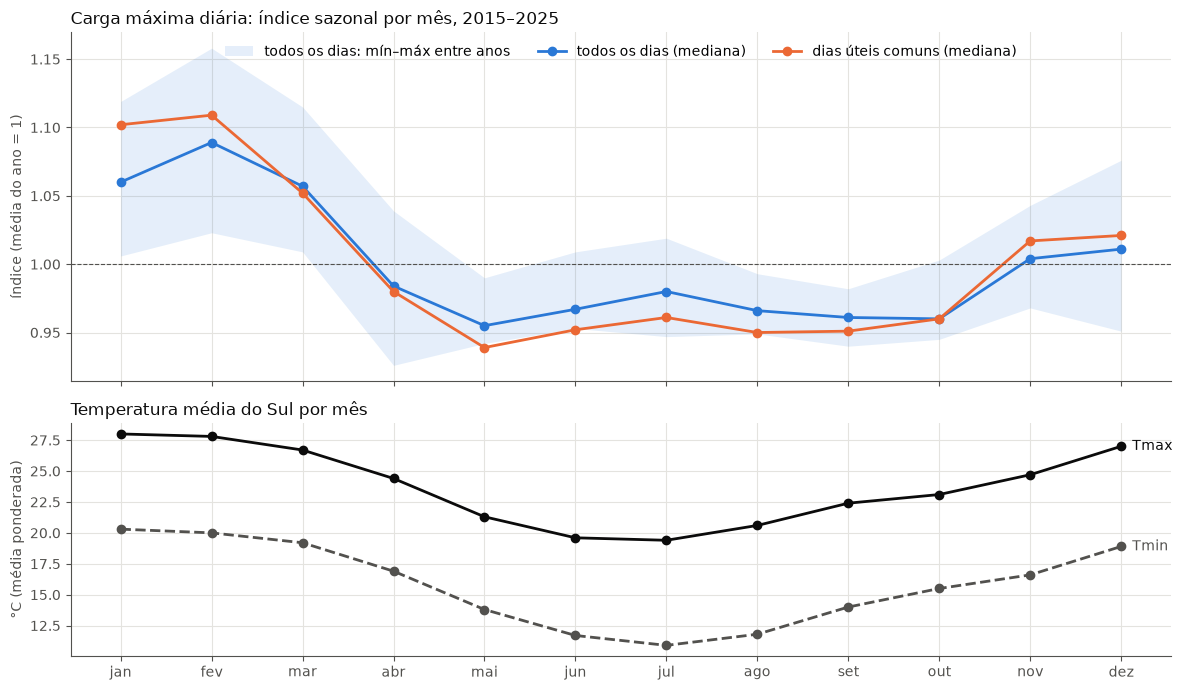

In [10]:
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
x = sazonal_mes["mes"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, height_ratios=[3, 2])
ax1.fill_between(x, sazonal_mes["indice_todos_min"], sazonal_mes["indice_todos_max"],
                 color=COR[0], alpha=0.12, lw=0, label="todos os dias: mín–máx entre anos")
ax1.plot(x, sazonal_mes["indice_todos_mediana"], color=COR[0], marker="o", label="todos os dias (mediana)")
ax1.plot(x, sazonal_mes["indice_uteis_mediana"], color=COR[1], marker="o", label="dias úteis comuns (mediana)")
ax1.axhline(1, color=TINTA_2, lw=0.8, ls="--")
ax1.set_ylabel("índice (média do ano = 1)")
ax1.set_title("Carga máxima diária: índice sazonal por mês, 2015–2025", loc="left", color=TINTA)
ax1.legend(loc="upper center", ncols=3)

ax2.plot(x, sazonal_mes["tmax_media"], color=TINTA, marker="o")
ax2.plot(x, sazonal_mes["tmin_media"], color=TINTA_2, marker="o", ls="--")
ax2.annotate("Tmax", (12, sazonal_mes["tmax_media"].iloc[-1]), xytext=(8, 0), textcoords="offset points",
             va="center", color=TINTA)
ax2.annotate("Tmin", (12, sazonal_mes["tmin_media"].iloc[-1]), xytext=(8, 0), textcoords="offset points",
             va="center", color=TINTA_2)
ax2.set_ylabel("°C (média ponderada)")
ax2.set_title("Temperatura média do Sul por mês", loc="left", color=TINTA)
ax2.set_xticks(range(1, 13), MESES)
plt.tight_layout()

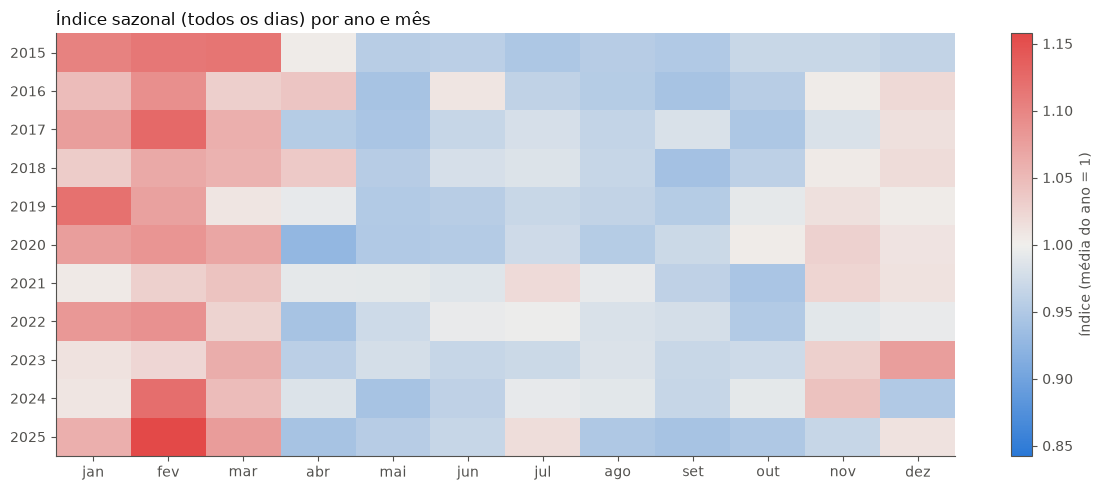

In [11]:
mapa = sql("SELECT ano, mes, indice_todos FROM sazonal_ano_mes").pivot(index="ano", columns="mes", values="indice_todos")
lim = float((mapa - 1).abs().max().max())

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(mapa, cmap=DIVERGENTE, norm=TwoSlopeNorm(1, 1 - lim, 1 + lim), aspect="auto")
ax.set_xticks(range(12), MESES)
ax.set_yticks(range(len(mapa)), mapa.index)
ax.grid(False)
ax.set_title("Índice sazonal (todos os dias) por ano e mês", loc="left", color=TINTA)
fig.colorbar(im, ax=ax, label="índice (média do ano = 1)")
plt.tight_layout()

> **Interpretação**
>
> A carga máxima tem dois patamares bem definidos. De dezembro a março ela fica acima da média do ano, com o pico em fevereiro (índice mediano de 1,089, cerca de 9% acima da média, e 15,5 GW em média). De abril a outubro ela fica cerca de 2% a 5% abaixo da média, com o mínimo em maio (0,955). Novembro é o mês de transição. A temperatura tem o mesmo desenho: os quatro meses de maior Tmax (jan, fev, dez, mar) são também os quatro de maior carga, e a correlação entre a mediana do índice de todos os dias (`indice_todos_mediana`) e a Tmax média (`tmax_media`) nos 12 meses é de 0,84. A sazonalidade da carga no Sul é comandada principalmente pelo calor do verão.
>
> A relação, porém, não é só linear. Julho é o mês mais frio (Tmax de 19,4 °C) e tem carga maior que maio, agosto, setembro e outubro (0,980, contra 0,955 a 0,966). Junho, quase tão frio, fica no nível desses meses (0,967). Esse pequeno pico de inverno em julho é compatível com o uso de aquecimento nos dias frios e é o primeiro sinal da forma em U testada em H3. O horário do pico também muda: nos dias úteis de verão o pico mais comum é às 14 h (ar-condicionado em comércio e serviços), e nos meses frios passa para 18–19 h (consumo residencial à noite).
>
> A curva dos dias úteis comuns tem amplitude maior que a de todos os dias (1,109 em fevereiro contra 0,939 em maio). Isso acontece porque a diferença entre fim de semana e dia útil muda ao longo do ano: no verão o fim de semana fica cerca de 18% abaixo do dia útil, e no inverno só 12% a 13%, provavelmente porque o pico residencial da noite depende menos do dia da semana. Em janeiro a distância entre as duas curvas é maior (1,060 contra 1,102) porque "todos os dias" incluem o recesso de fim de ano, de carga mais baixa. Ou seja, o efeito do dia da semana não é constante ao longo do ano.
>
> O mapa de calor mostra que o padrão se repete em todos os anos, com intensidade variável, e os desvios têm explicação conhecida:
> - fev/2025 é a célula mais alta (1,158) e é também o mês de maior Tmax média da série (30,0 °C);
> - dez/2023 (1,076) acompanha o calor do fim de 2023 (Tmax de 28,3 °C), enquanto dez/2024 (0,951) foi um dezembro mais ameno (26,0 °C);
> - abr/2020 é a célula mais baixa (0,926), o primeiro mês inteiro de isolamento da pandemia (as restrições começaram na segunda quinzena de março);
> - 2021 e o início de 2023 têm verões fracos no índice (jan–fev entre 1,006 e 1,029). Em parte, isso é um efeito do próprio índice: as mudanças de metodologia do ONS em mar/2021 e em 29/04/2023 elevaram a carga no resto desses anos, o que sobe a média anual e reduz o índice dos meses anteriores à mudança. O crescimento da carga dentro de cada ano tem um efeito parecido, mas menor, a favor dos últimos meses.
>
> O mês dá o padrão médio da carga, e a temperatura explica as diferenças entre anos que o mês sozinho não explica.

## 6. Hora do pico no verão e no inverno

**Pergunta:** a hora do pico muda entre verão e inverno? E ao longo dos anos?

A carga máxima diária é o alvo, mas a hora em que ela acontece diz qual temperatura e qual uso de energia formam o pico. Esta seção usa `hora_pico` da base diária e o perfil horário da base horária, só com dias úteis comuns. As horas estão no relógio local do ONS, com horário de verão até fev/2019: nesses verões, 14h no relógio correspondem a 13h sem o horário de verão.

### 6.1 Distribuição da hora do pico por mês

In [12]:
hora_mes = sql("""
SELECT mes,
       CAST(hora_pico AS INTEGER) AS hora,
       COUNT(*) AS n_dias,
       100 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY mes) AS pct_do_mes
FROM diaria_cal
WHERE tipo_dia = 'útil comum' AND NOT dia_incompleto
GROUP BY mes, hora
ORDER BY mes, hora
""")

sql("""
SELECT mes,
       CAST(SUM(n_dias) AS INTEGER) AS n_dias,
       ARG_MAX(hora, n_dias) AS hora_mais_comum,
       ROUND(SUM(pct_do_mes) FILTER (WHERE hora BETWEEN 12 AND 16), 1) AS pct_tarde_12_16h,
       ROUND(SUM(pct_do_mes) FILTER (WHERE hora BETWEEN 17 AND 22), 1) AS pct_noite_17_22h,
       ROUND(SUM(pct_do_mes) FILTER (WHERE hora < 12), 1) AS pct_manha
FROM hora_mes
GROUP BY mes
ORDER BY mes
""")

,mes,n_dias,hora_mais_comum,pct_tarde_12_16h,pct_noite_17_22h,pct_manha
0,1,196,14,89.8,6.1,4.1
1,2,198,14,88.9,6.6,4.5
2,3,229,14,72.9,18.3,8.7
3,4,187,18,44.4,44.9,10.7
4,5,220,18,5.5,85.9,8.6
5,6,211,18,0.9,96.2,2.8
6,7,243,18,1.2,91.8,7.0
7,8,244,18,5.3,79.1,15.6
8,9,204,19,20.6,59.8,19.6
9,10,219,19,28.8,42.9,28.3


### 6.2 Hora do pico de verão e de inverno em cada ano

In [13]:
hora_ano = sql(f"""
WITH dias AS (
    SELECT ano, regime_ons, CAST(hora_pico AS INTEGER) AS hora,
           CASE WHEN mes IN {VERAO} THEN 'verão' WHEN mes IN {INVERNO} THEN 'inverno' END AS estacao
    FROM diaria_cal
    WHERE tipo_dia = 'útil comum' AND NOT dia_incompleto
)
SELECT ano, estacao,
       list_sort(list(DISTINCT regime_ons)) AS regimes,
       COUNT(*) AS n_dias,
       MODE(hora) AS hora_mais_comum,
       ROUND(100 * AVG(CAST(hora BETWEEN 12 AND 16 AS INTEGER)), 1) AS pct_12_16h,
       ROUND(100 * AVG(CAST(hora BETWEEN 17 AND 22 AS INTEGER)), 1) AS pct_17_22h,
       ROUND(100 * AVG(CAST(hora < 12 AS INTEGER)), 1) AS pct_manha
FROM dias
WHERE estacao IS NOT NULL
GROUP BY ano, estacao
ORDER BY estacao DESC, ano
""")
hora_ano

,ano,estacao,regimes,n_dias,hora_mais_comum,pct_12_16h,pct_17_22h,pct_manha
0,2015,verão,[0],52,14,94.2,0.0,5.8
1,2016,verão,[0],52,14,98.1,0.0,1.9
2,2017,verão,[0],51,14,98.0,0.0,2.0
3,2018,verão,[0],50,14,96.0,0.0,4.0
4,2019,verão,[0],55,14,90.9,1.8,7.3
5,2020,verão,[0],53,14,88.7,3.8,7.5
6,2021,verão,"[0, 1]",51,16,96.1,2.0,2.0
7,2022,verão,[1],53,16,69.8,26.4,3.8
8,2023,verão,"[1, 2]",50,21,50.0,38.0,12.0
9,2024,verão,[2],52,14,78.8,5.8,15.4


### 6.3 Perfil horário médio por estação e regime do ONS

Cada hora é dividida pela carga máxima do próprio dia, de modo que o perfil mostra a forma da curva, e não o nível. A hora inexistente das trocas de horário de verão fica de fora.

In [14]:
perfil = sql(f"""
SELECT CASE WHEN d.mes IN {VERAO} THEN 'verão' ELSE 'inverno' END AS estacao,
       d.regime_ons,
       hour(h.instante) AS hora,
       COUNT(*) AS n_horas,
       AVG(h.carga / d.carga_max) AS carga_rel
FROM read_parquet('{DIR_PROC / "base_horaria.parquet"}') h
JOIN diaria_cal d ON d.data = CAST(h.data AS DATE)
WHERE d.tipo_dia = 'útil comum' AND NOT d.dia_incompleto
  AND NOT h.hora_inexistente_dst AND h.carga IS NOT NULL
  AND (d.mes IN {VERAO} OR d.mes IN {INVERNO})
GROUP BY ALL
ORDER BY estacao, regime_ons, hora
""")

perfil.pivot_table(index="hora", columns=["estacao", "regime_ons"], values="carga_rel").round(3).loc[[3, 10, 14, 16, 18, 20, 21]]

estacao    inverno                verão              
regime_ons       0      1      2      0      1      2
hora                                                 
3            0.595  0.596  0.587  0.664  0.730  0.673
10           0.957  0.868  0.909  0.953  0.899  0.950
14           0.943  0.853  0.869  0.997  0.961  0.992
16           0.952  0.911  0.905  0.981  0.986  0.977
18           0.995  0.998  0.996  0.848  0.905  0.883
20           0.918  0.926  0.938  0.863  0.968  0.933
21           0.904  0.891  0.896  0.878  0.969  0.923

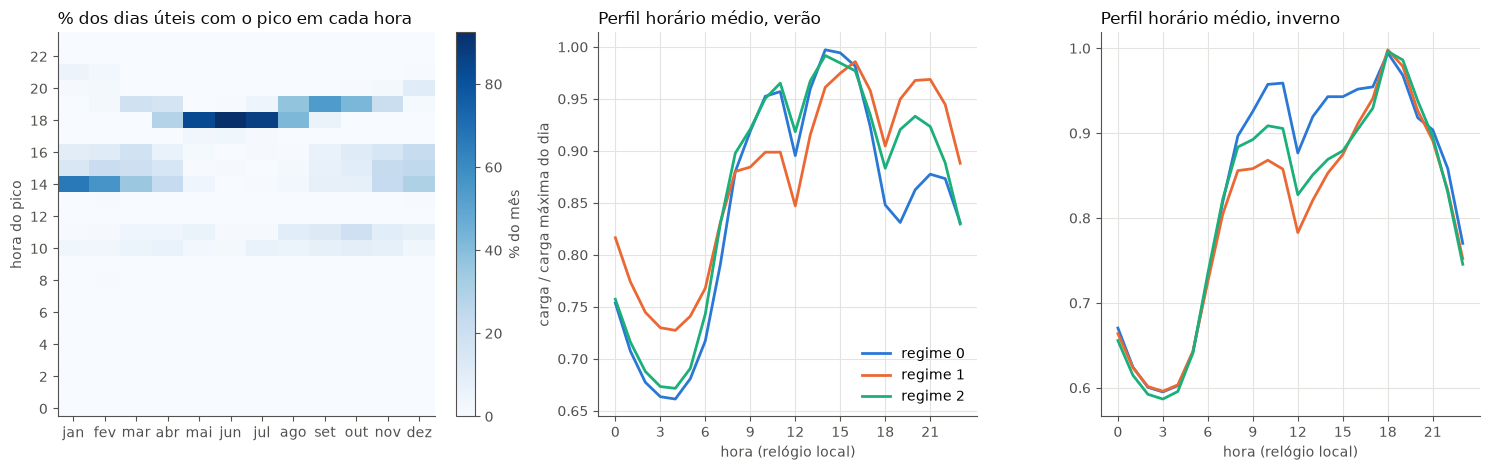

In [15]:
mapa_hora = hora_mes.pivot(index="hora", columns="mes", values="pct_do_mes").reindex(range(24)).fillna(0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), width_ratios=[1.1, 1, 1])
im = axes[0].imshow(mapa_hora, aspect="auto", cmap="Blues", origin="lower")
axes[0].set_xticks(range(12), MESES)
axes[0].set_yticks(range(0, 24, 2))
axes[0].set_ylabel("hora do pico")
axes[0].grid(False)
axes[0].set_title("% dos dias úteis com o pico em cada hora", loc="left", color=TINTA)
fig.colorbar(im, ax=axes[0], fraction=0.046, label="% do mês")

for ax, estacao in zip(axes[1:], ["verão", "inverno"]):
    for r in range(3):
        p = perfil[(perfil["estacao"] == estacao) & (perfil["regime_ons"] == r)]
        ax.plot(p["hora"], p["carga_rel"], color=COR[r], label=f"regime {r}")
    ax.set_title(f"Perfil horário médio, {estacao}", loc="left", color=TINTA)
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("hora (relógio local)")
axes[1].set_ylabel("carga / carga máxima do dia")
axes[1].legend(loc="lower right")
plt.tight_layout()

> **Interpretação**
>
> A hora do pico tem dois regimes ao longo do ano. De dezembro a fevereiro, de 77% a 90% dos dias úteis têm o pico entre 12h e 16h, quase sempre às 14h. De maio a agosto, de 79% a 96% dos dias têm o pico entre 17h e 22h, quase sempre às 18h. Março e novembro ficam mais perto do verão, abril e outubro se dividem entre os dois horários, e em setembro e outubro o pico noturno passa para as 19h. O pico de verão no começo da tarde coincide com a hora mais quente do dia, o que é compatível com o uso de ar-condicionado e com o efeito do calor medido em H1. O pico de inverno no fim da tarde coincide com o fim do horário comercial e o início do consumo residencial. O perfil horário mostra os dois formatos. No verão a curva tem um platô das 10h às 16h, com uma queda ao meio-dia (horário de almoço). No inverno ela sobe até um pico estreito às 18h.
>
> O pico de verão mudou de hora entre 2020 e 2023 e depois voltou. De 2015 a 2020, de 89% a 98% dos dias de verão têm o pico entre 12h e 16h, quase sempre às 14h. Em 2021 e 2022 a hora mais comum passa para as 16h. Em 2022, 26% dos dias já têm o pico à noite, e em 2023 são 38%, com a hora mais comum às 21h. Em 2024 e 2025 o pico volta às 14h. A mudança coincide com o regime 1 do ONS (mar/2021 a abr/2023), e o perfil horário mostra o mecanismo. No regime 1 a carga do meio do dia é bem menor em relação ao pico (às 14h do inverno, 0,853 contra 0,943 no regime 0), e o perfil de verão fica quase plano entre 14h e 21h. Isso é o que se espera quando a geração distribuída solar (MMGD) cresce e não é somada à carga: ela reduz a carga medida justamente nas horas de sol. O regime 2, que soma a MMGD estimada, devolve o perfil ao formato do regime 0. O deslocamento já aparece em 2020 e no começo de 2021, ainda no regime 0, o que combina com o crescimento da MMGD antes da troca de metodologia.
>
> Dois pontos ficam em aberto. No inverno de 2015, 46% dos dias têm o pico de manhã (10h), e em 2016 são 29%. Depois disso, quase nenhum. Não identificamos a causa, que pode estar nos dados do ONS desses anos. O fim do horário de verão, em 2019, também não mudou a hora mais comum do pico de verão, que continua às 14h no relógio. Isso sugere que o pico segue mais o horário das atividades do que a hora solar, mas os dados não permitem separar os dois efeitos.
>
> Para a previsão de D+1:
> - a temperatura que forma o pico depende da estação: no verão é a do começo da tarde, perto da Tmax; no inverno o pico é às 18h, e a Tmax pesa menos. Uma interação entre temperatura e estação (ou mês) deve ajudar os modelos;
> - `regime_ons` precisa entrar como atributo, porque a metodologia muda o formato da curva e não só o nível. O regime 1 tem picos de verão mais baixos em relação à carga do meio do dia, o que afeta os lags e as médias móveis desse período;
> - a hora do pico não é o alvo, mas o deslocamento de 2021–2023 é mais um motivo para não comparar diretamente os erros de anos de regimes diferentes.


## 7. Quanto se perde ao agregar de diário para semanal e mensal

**Pergunta:** quanta variabilidade se perde ao agregar de diário para semanal e mensal? A relação com a temperatura fica mais forte ou mais fraca?

A granularidade diária foi escolhida na proposta. Esta seção verifica a escolha com as três bases da Etapa 2. Nas bases semanal e mensal, a carga é `carga_max_media` (média das cargas máximas diárias do período) e a temperatura é `tmax_media`. Os períodos incompletos ficam de fora. Como nas seções 5 e 9, a carga também é dividida pela média do próprio ano (o índice), para que a tendência de crescimento não infle a dispersão nem a correlação.

### 7.1 Dispersão e correlação com o clima em cada granularidade

In [16]:
con.sql(f"""
CREATE OR REPLACE VIEW granularidades AS
WITH juntas AS (
    SELECT 'diária' AS granularidade, 1 AS ordem, year(data) AS ano,
           carga_max, tmax, cdd, hdd
    FROM diaria
    WHERE NOT dia_incompleto
    UNION ALL
    SELECT 'semanal', 2, year(semana_inicio + INTERVAL 3 DAY),   -- ano da quinta-feira (semana ISO)
           carga_max_media, tmax_media, cdd, hdd
    FROM read_parquet('{DIR_PROC / "base_semanal.parquet"}')
    WHERE NOT periodo_incompleto
    UNION ALL
    SELECT 'mensal', 3, year(mes),
           carga_max_media, tmax_media, cdd, hdd
    FROM read_parquet('{DIR_PROC / "base_mensal.parquet"}')
    WHERE NOT periodo_incompleto
)
SELECT *, carga_max / AVG(carga_max) OVER (PARTITION BY granularidade, ano) AS indice
FROM juntas
""")

sql("""
SELECT granularidade,
       COUNT(*) AS n_periodos,
       ROUND(100 * STDDEV_SAMP(carga_max) / AVG(carga_max), 2) AS cv_mw_pct,
       ROUND(100 * STDDEV_SAMP(indice), 2) AS cv_indice_pct,
       ROUND(CORR(carga_max, tmax), 3) AS r_mw_tmax,
       ROUND(CORR(indice, tmax), 3) AS r_indice_tmax,
       ROUND(CORR(indice, cdd), 3) AS r_indice_cdd,
       ROUND(CORR(indice, hdd), 3) AS r_indice_hdd
FROM granularidades
GROUP BY granularidade, ordem
ORDER BY ordem
""")

,granularidade,n_periodos,cv_mw_pct,cv_indice_pct,r_mw_tmax,r_indice_tmax,r_indice_cdd,r_indice_hdd
0,diária,4017,13.85,10.42,0.320,0.369,0.339,-0.122
1,semanal,573,11.11,6.31,0.398,0.594,0.556,-0.282
2,mensal,132,10.43,4.94,0.406,0.699,0.698,-0.400


### 7.2 Onde fica a variação diária

A variância do índice diário é dividida em duas partes: a variação dentro da semana (ou do mês), que some na agregação, e a variação entre semanas (ou meses), que sobrevive a ela. A segunda consulta mede o quanto o pico do período fica acima da média das cargas máximas diárias: é a informação que uma previsão semanal ou mensal da média não enxerga.

In [17]:
sql("""
WITH dias AS (
    SELECT data,
           carga_max / AVG(carga_max) OVER (PARTITION BY ano) AS indice,
           date_trunc('week', data) AS semana,
           date_trunc('month', data) AS mes_ini
    FROM diaria
    WHERE NOT dia_incompleto
),
medias AS (
    SELECT indice,
           AVG(indice) OVER (PARTITION BY semana) AS media_semana,
           AVG(indice) OVER (PARTITION BY mes_ini) AS media_mes
    FROM dias
)
SELECT ROUND(100 * STDDEV_POP(indice), 2) AS dp_indice_diario_pct,
       ROUND(100 * AVG((indice - media_semana) ^ 2) / VAR_POP(indice), 1) AS pct_var_dentro_da_semana,
       ROUND(100 * AVG((indice - media_mes) ^ 2) / VAR_POP(indice), 1) AS pct_var_dentro_do_mes
FROM medias
""")

,dp_indice_diario_pct,pct_var_dentro_da_semana,pct_var_dentro_do_mes
0,10.42,63.0,78.0


In [18]:
sql(f"""
WITH picos AS (
    SELECT 'semanal' AS granularidade, 1 AS ordem, 100 * (carga_max_max / carga_max_media - 1) AS pico_acima_pct
    FROM read_parquet('{DIR_PROC / "base_semanal.parquet"}')
    WHERE NOT periodo_incompleto
    UNION ALL
    SELECT 'mensal', 2, 100 * (carga_max_max / carga_max_media - 1)
    FROM read_parquet('{DIR_PROC / "base_mensal.parquet"}')
    WHERE NOT periodo_incompleto
)
SELECT granularidade,
       COUNT(*) AS n_periodos,
       ROUND(MEDIAN(pico_acima_pct), 1) AS mediana_pct,
       ROUND(QUANTILE_CONT(pico_acima_pct, 0.9), 1) AS p90_pct,
       ROUND(MAX(pico_acima_pct), 1) AS max_pct
FROM picos
GROUP BY granularidade, ordem
ORDER BY ordem
""")

,granularidade,n_periodos,mediana_pct,p90_pct,max_pct
0,semanal,573,7.4,13.0,21.9
1,mensal,132,13.5,20.5,27.2


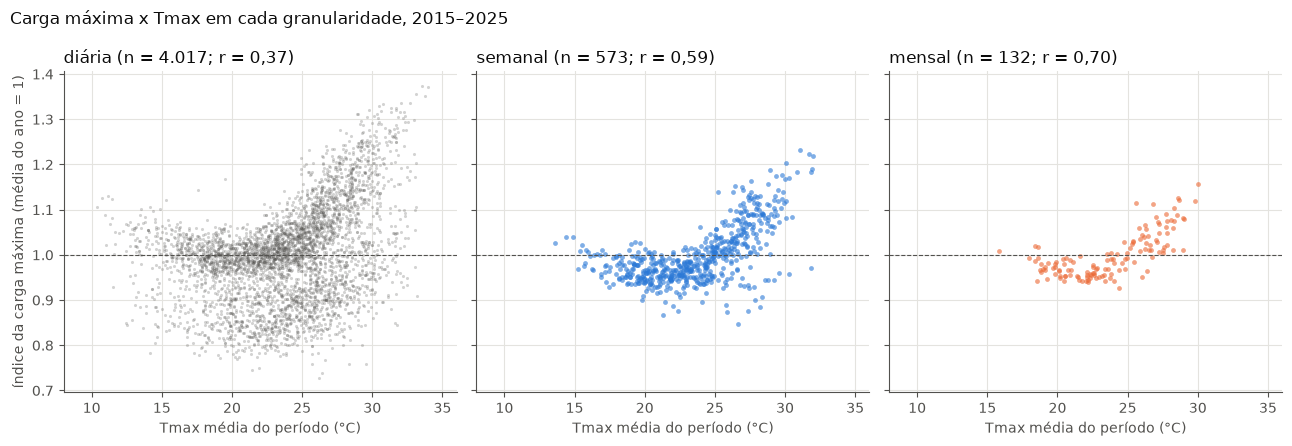

In [19]:
gran = sql("SELECT granularidade, tmax, indice FROM granularidades")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharex=True, sharey=True)
for ax, (nome, cor) in zip(axes, [("diária", TINTA_2), ("semanal", COR[0]), ("mensal", COR[1])]):
    g = gran[gran["granularidade"] == nome]
    ax.scatter(g["tmax"], g["indice"], s=5 if nome == "diária" else 12, color=cor,
               alpha=0.25 if nome == "diária" else 0.6, lw=0)
    ax.axhline(1, color=TINTA_2, lw=0.8, ls="--")
    r = g["indice"].corr(g["tmax"])
    ax.set_title(f"{nome} (n = {len(g):,}".replace(",", ".") + f"; r = {r:.2f})".replace(".", ","),
                 loc="left", color=TINTA)
    ax.set_xlabel("Tmax média do período (°C)")
    ax.set_xlim(*FAIXA_DISPERSAO)
axes[0].set_ylabel("índice da carga máxima (média do ano = 1)")
fig.suptitle("Carga máxima x Tmax em cada granularidade, 2015–2025", x=0.01, ha="left", color=TINTA)
plt.tight_layout()

> **Interpretação**
>
> Agregar reduz bastante a dispersão. O coeficiente de variação do índice cai de 10,4% no diário para 6,3% no semanal e 4,9% no mensal. Em MW a queda é menor (de 13,9% para 10,4%), porque a tendência de crescimento entre os anos continua presente em todas as granularidades. A decomposição da 7.2 mostra para onde vai essa variação: 63% da variância do índice diário está dentro da semana e 78% dentro do mês. Uma previsão semanal descartaria quase dois terços da variação que queremos prever, e uma mensal, quase quatro quintos. Boa parte dessa variação é de calendário (fim de semana −15%, feriados −14%, seção 3.2) e de dias quentes isolados.
>
> A correlação com a temperatura fica mais forte com a agregação: de 0,37 no diário para 0,59 no semanal e 0,70 no mensal (índice contra Tmax). Isso não quer dizer que a temperatura pese mais na escala mensal. A agregação apaga a variação de calendário, que não tem relação com a temperatura e funciona como ruído na correlação diária. Os gráficos mostram que o U da seção 9 continua nas três granularidades, então a correlação linear subestima a relação em todas elas. A correlação com os graus-dia de aquecimento (`hdd`) é negativa em todas as escalas, porque o ramo frio do U é muito mais fraco que o ramo quente.
>
> O pico também se perde. Na mediana, o maior dia da semana fica 7,4% acima da média das cargas máximas da semana (P90 de 13%), e o maior dia do mês fica 13,5% acima da média do mês (P90 de 20,5%). Um modelo que prevê a média semanal ou mensal erra o pico por essa margem, mesmo que acerte a média.
>
> A conclusão confirma a granularidade diária da proposta. O problema é prever o pico do dia seguinte, e a maior parte da variação está dentro da semana. A correlação mais alta das bases agregadas não é motivo para agregar. Para a Etapa 4, a escala semanal entra como atributo de nível (média móvel de 7 dias da carga máxima), e o calendário (dia da semana, feriados) precisa ser atributo explícito, porque responde pela maior parte da variação dentro da semana.


## 8. Teste de H2 – feriados

**Hipótese:** a carga máxima em feriados que caem em dias de semana é menor do que a de dias úteis comparáveis (mesmo dia da semana e mesmo mês). H0: diferença ≥ 0; H1: diferença < 0.

### 8.1 Pareamento de cada feriado com dias úteis comparáveis

Cada feriado em dia de semana é comparado com a média dos dias úteis comuns do **mesmo dia da semana, mesmo mês, mesmo ano e mesmo regime do ONS**. A proposta falava em mesmo dia da semana e mesmo mês; o ano e o regime entraram porque a carga cresceu mais de 30% no período e tem degraus nas trocas de regime (seção 4). Sem esse controle, a comparação misturaria o efeito do feriado com a tendência. Os controles são só dias `útil comum`, então ponte, véspera, pós-feriado e recesso ficam fora. Como cada feriado tem o seu próprio grupo de controle, o teste é pareado: a medida é a diferença % de cada feriado em relação aos seus controles.

In [20]:
con.sql("""
CREATE OR REPLACE VIEW h2_pares AS
WITH feriados AS (
    SELECT data, ano, mes, dia_semana, regime_ons, nome_feriado, feriado_nacional, pandemia, carga_max, tmax
    FROM diaria_cal
    WHERE feriado AND NOT fim_de_semana AND NOT dia_incompleto
),
controles AS (
    SELECT ano, mes, dia_semana, regime_ons,
           COUNT(*) AS n_controles,
           AVG(carga_max) AS carga_controle,
           AVG(tmax) AS tmax_controle
    FROM diaria_cal
    WHERE tipo_dia = 'útil comum' AND NOT dia_incompleto
    GROUP BY ano, mes, dia_semana, regime_ons
)
SELECT f.*, c.n_controles, c.carga_controle, c.tmax_controle,
       100 * (f.carga_max / c.carga_controle - 1) AS diferenca_pct,
       f.tmax - c.tmax_controle AS diferenca_tmax
FROM feriados f
LEFT JOIN controles c USING (ano, mes, dia_semana, regime_ons)
""")

sql(f"""
SELECT CASE WHEN feriado_nacional THEN 'nacional' ELSE 'estadual' END AS tipo,
       COUNT(*) AS n_feriados_dia_semana,
       COUNT(*) FILTER (WHERE n_controles >= {MIN_CONTROLES}) AS n_pareados,
       ROUND(AVG(n_controles), 1) AS controles_por_feriado,
       ROUND(AVG(diferenca_tmax), 2) AS diferenca_tmax_media
FROM h2_pares
GROUP BY tipo
ORDER BY tipo DESC
""")

,tipo,n_feriados_dia_semana,n_pareados,controles_por_feriado,diferenca_tmax_media
0,nacional,110,110,3.2,0.33
1,estadual,8,8,2.0,0.15


### 8.2 Teste da diferença pareada

O teste t de uma amostra sobre as diferenças pareadas equivale ao teste t pareado. Como complemento não paramétrico, usamos o teste de Wilcoxon dos postos sinalizados, que é a versão pareada do Mann-Whitney citado na proposta: os dois grupos não são independentes, porque cada feriado tem os seus controles. Os dois testes são unilaterais (H1: diferença < 0). O teste principal usa só os feriados nacionais. O Dia do Gaúcho (RS) vale para cerca de 36% da população do Sul e entra como recorte separado. O Carnaval responde por 22 dos 110 feriados nacionais e não é feriado em todo lugar (muitas vezes é ponto facultativo), por isso há também recortes com e sem ele.

In [21]:
pares_h2 = sql(f"SELECT * FROM h2_pares WHERE n_controles >= {MIN_CONTROLES} ORDER BY data")


def teste_h2(diferencas):
    """Diferença média (%) com IC 95% (t) e testes unilaterais de H0: diferença >= 0."""
    d = diferencas.dropna()
    n = len(d)
    ic = stats.t.interval(0.95, n - 1, loc=d.mean(), scale=stats.sem(d)) if n > 1 else (np.nan, np.nan)
    return {
        "n": n,
        "diferenca_media_pct": d.mean(),
        "ic95_inf": ic[0],
        "ic95_sup": ic[1],
        "mediana_pct": d.median(),
        "frac_abaixo_controle": (d < 0).mean(),
        "p_t": stats.ttest_1samp(d, 0, alternative="less").pvalue if n > 1 else np.nan,
        "p_wilcoxon": stats.wilcoxon(d, alternative="less").pvalue if n > 1 else np.nan,
    }


nacionais = pares_h2[pares_h2["feriado_nacional"]]
recortes = {
    "nacionais (teste principal)": nacionais,
    "nacionais sem Carnaval": nacionais[nacionais["nome_feriado"] != "Carnaval"],
    "só Carnaval": nacionais[nacionais["nome_feriado"] == "Carnaval"],
    "nacionais sem 2020 (pandemia)": nacionais[nacionais["ano"] != 2020],
    **{f"nacionais, regime_ons = {r}": nacionais[nacionais["regime_ons"] == r] for r in range(3)},
    "estadual: Dia do Gaúcho (RS)": pares_h2[~pares_h2["feriado_nacional"]],
}
resultado_h2 = pd.DataFrame({nome: teste_h2(d["diferenca_pct"]) for nome, d in recortes.items()}).T
resultado_h2.style.format({"n": "{:.0f}", "diferenca_media_pct": "{:.1f}", "ic95_inf": "{:.1f}", "ic95_sup": "{:.1f}",
                           "mediana_pct": "{:.1f}", "frac_abaixo_controle": "{:.0%}", "p_t": "{:.1e}", "p_wilcoxon": "{:.1e}"})

,n,diferenca_media_pct,ic95_inf,ic95_sup,mediana_pct,frac_abaixo_controle,p_t,p_wilcoxon
nacionais (teste principal),110,-14.7,-16.3,-13.0,-14.0,97%,3.7e-34,1.1e-19
nacionais sem Carnaval,88,-15.8,-17.5,-14.0,-14.2,100%,2.1e-31,1.9e-16
só Carnaval,22,-10.2,-14.4,-6.1,-12.7,86%,2.0e-05,8.8e-05
nacionais sem 2020 (pandemia),99,-14.7,-16.5,-12.9,-13.9,97%,1.6e-30,7.3e-18
"nacionais, regime_ons = 0",65,-16.8,-18.9,-14.7,-14.9,100%,1.2e-24,1.2e-12
"nacionais, regime_ons = 1",20,-11.2,-14.4,-8.1,-10.0,100%,2.5e-07,9.5e-07
"nacionais, regime_ons = 2",25,-11.8,-15.8,-7.9,-11.1,88%,9.3e-07,2.1e-06
estadual: Dia do Gaúcho (RS),8,-5.2,-7.6,-2.8,-6.0,88%,6.5e-04,7.8e-03


### 8.3 Diferença por feriado

In [22]:
por_feriado = (pd.DataFrame({nome: teste_h2(g["diferenca_pct"]) for nome, g in pares_h2.groupby("nome_feriado")}).T
               .join(pares_h2.groupby("nome_feriado")["diferenca_tmax"].mean().rename("diferenca_tmax_media"))
               .sort_values("diferenca_media_pct"))
por_feriado[["n", "diferenca_media_pct", "ic95_inf", "ic95_sup", "frac_abaixo_controle", "diferenca_tmax_media"]].style.format(
    {"n": "{:.0f}", "diferenca_media_pct": "{:.1f}", "ic95_inf": "{:.1f}", "ic95_sup": "{:.1f}",
     "frac_abaixo_controle": "{:.0%}", "diferenca_tmax_media": "{:.1f}"})

,n,diferenca_media_pct,ic95_inf,ic95_sup,frac_abaixo_controle,diferenca_tmax_media
Confraternização Universal,8,-30.4,-34.0,-26.8,100%,0.7
Natal,8,-25.8,-30.7,-20.9,100%,0.9
Sexta-feira Santa,11,-21.4,-24.5,-18.2,100%,-0.4
Finados,8,-17.3,-20.7,-14.0,100%,-3.1
Nossa Senhora Aparecida,8,-14.4,-15.7,-13.2,100%,0.1
Independência do Brasil,8,-11.4,-14.2,-8.7,100%,-0.7
Dia do Trabalhador,8,-11.3,-13.2,-9.4,100%,1.7
Proclamação da República,8,-11.0,-15.5,-6.5,100%,1.3
Carnaval,22,-10.2,-14.4,-6.1,86%,0.6
Corpus Christi,11,-8.5,-10.9,-6.1,100%,1.4


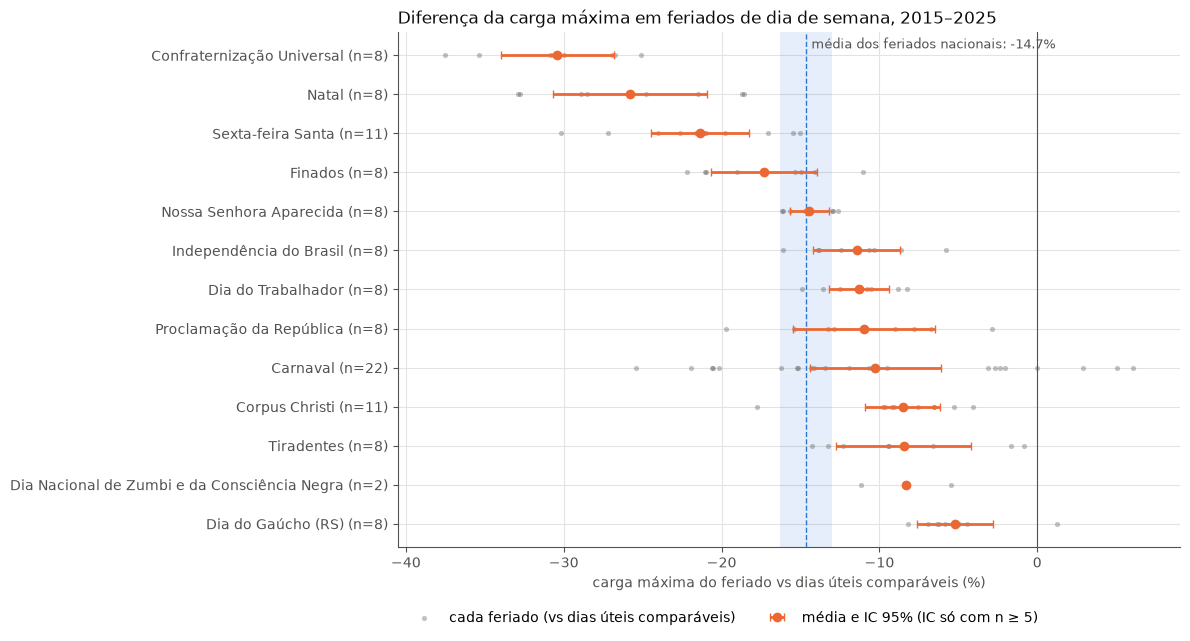

In [23]:
MIN_N_IC = 5
ordem = por_feriado.index.tolist()
y = {nome: i for i, nome in enumerate(ordem)}
principal = resultado_h2.loc["nacionais (teste principal)"]

fig, ax = plt.subplots(figsize=(12, 6.5))
ax.axvspan(principal["ic95_inf"], principal["ic95_sup"], color=COR[0], alpha=0.12, lw=0)
ax.axvline(principal["diferenca_media_pct"], color=COR[0], lw=1, ls="--")
ax.annotate(f"média dos feriados nacionais: {principal['diferenca_media_pct']:.1f}%",
            (principal["diferenca_media_pct"], 1), xycoords=("data", "axes fraction"),
            xytext=(4, -4), textcoords="offset points", va="top", color=TINTA_2, fontsize=9)
ax.axvline(0, color=TINTA_2, lw=0.8)
ax.scatter(pares_h2["diferenca_pct"], pares_h2["nome_feriado"].map(y), s=14, color=TINTA_2, alpha=0.35, lw=0,
           label="cada feriado (vs dias úteis comparáveis)")
com_ic = por_feriado["n"] >= MIN_N_IC
ax.errorbar(por_feriado["diferenca_media_pct"], range(len(ordem)),
            xerr=[(por_feriado["diferenca_media_pct"] - por_feriado["ic95_inf"]).where(com_ic, 0),
                  (por_feriado["ic95_sup"] - por_feriado["diferenca_media_pct"]).where(com_ic, 0)],
            color=COR[1], marker="o", ls="none", capsize=3, label=f"média e IC 95% (IC só com n ≥ {MIN_N_IC})")
margem = 3
ax.set_xlim(pares_h2["diferenca_pct"].min() - margem, max(pares_h2["diferenca_pct"].max(), 0) + margem)
ax.set_yticks(range(len(ordem)), [f"{nome} (n={int(por_feriado.loc[nome, 'n'])})" for nome in ordem])
ax.invert_yaxis()
ax.set_xlabel("carga máxima do feriado vs dias úteis comparáveis (%)")
ax.set_title("Diferença da carga máxima em feriados de dia de semana, 2015–2025", loc="left", color=TINTA)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncols=2)
plt.tight_layout()

### 8.4 Ajuste pela temperatura e tendência do efeito

O pareamento controla o calendário, mas não a temperatura: um feriado pode ter sido mais quente ou mais frio que os seus controles. A regressão abaixo estima a diferença com a mesma Tmax (`diferenca_tmax = 0`). O segundo modelo acrescenta o ano, centrado em 2025 (o ano de teste), para verificar se o efeito do feriado mudou ao longo do tempo. Os erros-padrão são robustos (HC3). Aqui não se usa Newey-West, como na seção 10, porque os feriados ficam espaçados no calendário e não formam uma sequência de dias seguidos.

In [24]:
nac = pares_h2[pares_h2["feriado_nacional"]].assign(anos_desde_2025=lambda d: d["ano"] - 2025)
modelos_h2 = {
    "diferença ~ Tmax": ["diferenca_tmax"],
    "diferença ~ Tmax + ano": ["diferenca_tmax", "anos_desde_2025"],
}
linhas = []
for nome, x in modelos_h2.items():
    ajuste = sm.OLS(nac["diferenca_pct"], sm.add_constant(nac[x])).fit(cov_type="HC3")
    ic = ajuste.conf_int()
    for termo in ["const"] + x:
        linhas.append({"modelo": nome, "termo": termo, "coef": ajuste.params[termo],
                       "ic95_inf": ic.loc[termo, 0], "ic95_sup": ic.loc[termo, 1],
                       "p_valor": ajuste.pvalues[termo], "r2": ajuste.rsquared})
ajuste_h2 = pd.DataFrame(linhas).set_index(["modelo", "termo"])
ajuste_h2.style.format({"coef": "{:.2f}", "ic95_inf": "{:.2f}", "ic95_sup": "{:.2f}", "p_valor": "{:.1e}", "r2": "{:.2f}"})

> **Interpretação**
>
> Os 110 feriados nacionais que caíram em dia de semana entre 2015 e 2025 foram todos pareados, com 3,2 dias úteis de controle em média. Feriados e controles tiveram temperatura parecida (o feriado ficou 0,3 °C mais quente, em média). A carga máxima dos feriados ficou, em média, **14,7% abaixo** da dos dias úteis comparáveis (IC 95% de −16,3% a −13,0%; mediana de −14,0%), e 97% dos feriados ficaram abaixo dos seus controles. Os dois testes unilaterais rejeitam H0 com folga (p de 3,7e-34 no t e de 1,1e-19 no Wilcoxon). Os dados sustentam H2. O valor bate com a ordem de grandeza da seção 3.2 (−14%), que não controlava mês nem dia da semana.
>
> O resultado não depende dos recortes. Sem o Carnaval, a diferença vai para −15,8%, e todos os 88 feriados ficam abaixo dos controles. Sem 2020 (pandemia), fica em −14,7%. Nos três regimes do ONS os ICs excluem o zero, mas o efeito é menor nos regimes mais recentes: −16,8% no regime 0, contra −11,2% e −11,8% nos regimes 1 e 2. O Dia do Gaúcho, que vale só para o RS, reduz a carga do Sul em 5,2% (IC de −7,6% a −2,8%). Isso é próximo do que se espera se o RS, com 36% da população, tivesse a queda média de um feriado nacional (0,36 × 14,7% ≈ 5,3%). Esse resultado apoia o uso de `frac_pop_feriado_estadual` como atributo proporcional.
>
> O efeito varia muito entre feriados:
> - Confraternização Universal (−30,4%) e Natal (−25,8%) têm as maiores quedas, mas parte delas vem do recesso de fim de ano: os controles do Natal são dias de dezembro antes do dia 24, e os de 1º de janeiro são dias depois de 6 de janeiro;
> - Sexta-feira Santa (−21,4%) e Finados (−17,3%) vêm em seguida; Finados foi 3,1 °C mais frio que os controles, o que responde por parte da queda;
> - Nossa Senhora Aparecida fica na média (−14,4%);
> - os demais ficam entre −8,5% e −11,4%, com Corpus Christi e Tiradentes no fim da lista;
> - o Carnaval tem a maior dispersão (−10,3%, IC de −14,4% a −6,1%). Em 2024 e 2025, três dos quatro dias ficaram acima dos controles, e todos foram de 4 a 5 °C mais quentes que eles;
> - o Dia da Consciência Negra só virou feriado nacional em 2024 (2 dias), e não há dados para um IC.
>
> O ajuste da 8.4 confirma que a temperatura não explica o efeito. Com a mesma Tmax, a diferença é de −15,0% (IC de −16,6% a −13,5%), praticamente igual à diferença sem ajuste. Cada °C a mais no feriado, em relação aos controles, reduz a queda em 1,1 pp, o que explica o Carnaval quente. O segundo modelo mostra que o efeito do feriado ficou mais fraco ao longo do tempo: a queda diminui 0,78 pp por ano (IC de 0,28 a 1,28; p = 0,002). A diferença estimada para 2025, com a mesma Tmax, é de −11,0% (IC de −14,1% a −7,9%), contra cerca de −18,8% em 2015. Essa tendência não pode ser separada da troca de regime do ONS, porque os regimes mais recentes são justamente os anos finais.
>
> Para a previsão de D+1:
> - os feriados precisam de atributos próprios, porque a queda média (−15%) equivale a mais de cinco graus de Tmax na inclinação de H1 (2,8 pp por °C);
> - uma marcação binária de feriado não basta: os grandes feriados (Natal, Ano Novo, Sexta-feira Santa) caem duas a três vezes mais que os outros, e o Carnaval depende do calor;
> - o efeito médio estimado em 2015–2024 é maior que o de 2025. Um modelo que trate o feriado como efeito constante tende a prever quedas grandes demais no ano de teste. Vale incluir o ano ou o regime como atributo, ou dar mais peso aos anos recentes, e analisar os erros em feriados separadamente, como prevê a proposta.

## 9. Carga máxima por faixa de temperatura máxima

**Pergunta:** qual é a carga máxima média em cada faixa de Tmax? A curva tem forma de U?

### 9.1 Dias úteis comuns com índice (visão de apoio)

In [25]:
con.sql(f"""
CREATE OR REPLACE VIEW uteis_indice AS
WITH base AS (
    SELECT data, ano, mes, regime_ons, tmax, carga_max
    FROM diaria_cal
    WHERE tipo_dia = 'útil comum'
      AND NOT dia_incompleto
      AND (NOT {EXCLUIR_PANDEMIA} OR ano NOT IN (SELECT DISTINCT ano FROM diaria WHERE pandemia))
),
ref_anual AS (
    SELECT ano, AVG(media_mes) AS carga_ref
    FROM (SELECT ano, mes, AVG(carga_max) AS media_mes FROM base GROUP BY ano, mes)
    GROUP BY ano
)
SELECT b.*,
       b.carga_max / r.carga_ref AS indice,
       FLOOR(b.tmax / {LARGURA_FAIXA}) * {LARGURA_FAIXA} AS faixa
FROM base b
JOIN ref_anual r USING (ano)
""")

sql("SELECT COUNT(*) AS n_dias, MIN(data) AS inicio, MAX(data) AS fim, list_sort(list(DISTINCT ano)) AS anos FROM uteis_indice")

,n_dias,inicio,fim,anos
0,2514,2015-01-07,2025-12-23,"[2015, 2016, 2017, 2018, 2019, 2020, 2021, 202..."


### 9.2 Índice por faixa de Tmax

In [26]:
faixas_tmax = sql(f"""
SELECT faixa AS faixa_ini,
       faixa + {LARGURA_FAIXA} AS faixa_fim,
       COUNT(*) AS n_dias,
       ROUND(AVG(carga_max)) AS carga_max_media_mw,
       ROUND(AVG(indice), 4) AS indice_medio,
       ROUND(1.96 * STDDEV_SAMP(indice) / SQRT(COUNT(*)), 4) AS ic95,
       ROUND(100 * (AVG(indice) - LAG(AVG(indice)) OVER (ORDER BY faixa)), 2) AS variacao_pp_vs_faixa_anterior
FROM uteis_indice
GROUP BY faixa
HAVING COUNT(*) >= {MIN_DIAS_FAIXA}
ORDER BY faixa
""")
faixas_tmax

,faixa_ini,faixa_fim,n_dias,carga_max_media_mw,indice_medio,ic95,variacao_pp_vs_faixa_anterior
0,12.0,14.0,36,14743.0,0.987,0.009,NaN
1,14.0,16.0,72,14670.0,0.973,0.008,-1.40
2,16.0,18.0,174,14292.0,0.955,0.005,-1.87
3,18.0,20.0,273,14083.0,0.946,0.004,-0.92
4,20.0,22.0,289,14163.0,0.945,0.003,-0.03
5,22.0,24.0,436,14388.0,0.958,0.003,1.27
6,24.0,26.0,450,14810.0,0.989,0.004,3.11
7,26.0,28.0,382,15588.0,1.040,0.006,5.11
8,28.0,30.0,271,16451.0,1.090,0.008,5.03
9,30.0,32.0,100,17909.0,1.149,0.013,5.85


### 9.3 A mesma curva em cada regime do ONS

In [27]:
faixas_regime = sql(f"""
SELECT faixa AS faixa_ini,
       COUNT(*) FILTER (WHERE regime_ons = 0) AS n_r0,
       COUNT(*) FILTER (WHERE regime_ons = 1) AS n_r1,
       COUNT(*) FILTER (WHERE regime_ons = 2) AS n_r2,
       CASE WHEN n_r0 >= {MIN_DIAS_FAIXA} THEN ROUND(AVG(indice) FILTER (WHERE regime_ons = 0), 4) END AS indice_r0,
       CASE WHEN n_r1 >= {MIN_DIAS_FAIXA} THEN ROUND(AVG(indice) FILTER (WHERE regime_ons = 1), 4) END AS indice_r1,
       CASE WHEN n_r2 >= {MIN_DIAS_FAIXA} THEN ROUND(AVG(indice) FILTER (WHERE regime_ons = 2), 4) END AS indice_r2
FROM uteis_indice
GROUP BY faixa
ORDER BY faixa
""")
faixas_regime

,faixa_ini,n_r0,n_r1,n_r2,indice_r0,indice_r1,indice_r2
0,10.0,4,3,3,NaN,NaN,NaN
1,12.0,20,9,7,0.970,NaN,NaN
2,14.0,37,14,21,0.959,NaN,0.978
3,16.0,101,33,40,0.942,0.980,0.967
4,18.0,148,69,56,0.934,0.967,0.948
5,20.0,161,59,69,0.936,0.966,0.949
6,22.0,250,71,115,0.959,0.972,0.947
7,24.0,260,81,109,0.998,0.979,0.975
8,26.0,231,65,86,1.051,1.020,1.026
9,28.0,148,63,60,1.109,1.059,1.079


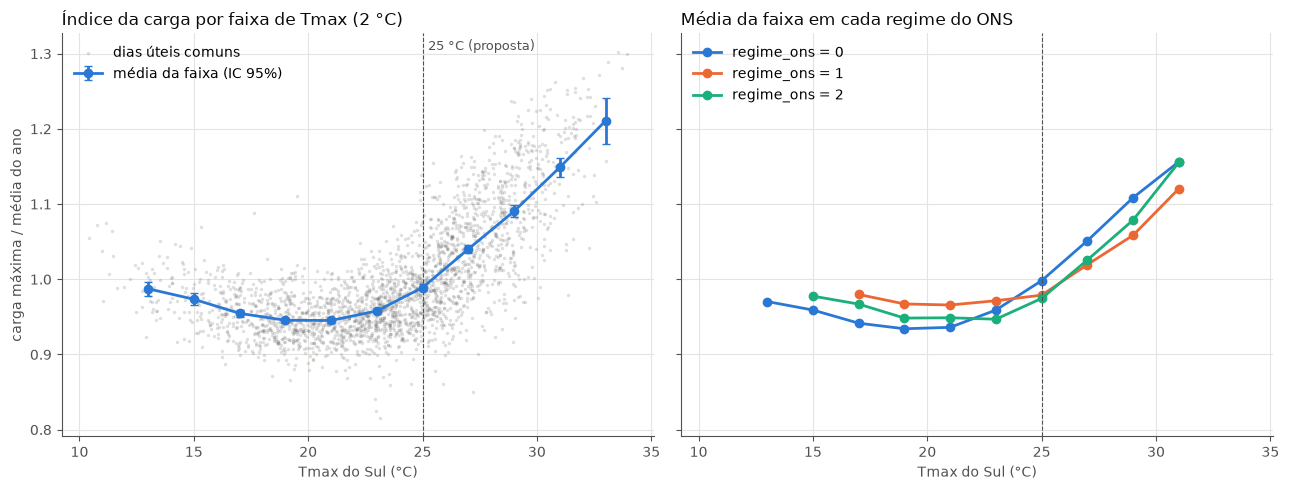

In [28]:
dias = sql("SELECT tmax, indice FROM uteis_indice")
centro = faixas_tmax["faixa_ini"] + LARGURA_FAIXA / 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
ax1.scatter(dias["tmax"], dias["indice"], s=6, color=TINTA_2, alpha=0.18, lw=0, label="dias úteis comuns")
ax1.errorbar(centro, faixas_tmax["indice_medio"], yerr=faixas_tmax["ic95"], color=COR[0], marker="o",
             capsize=3, label="média da faixa (IC 95%)")
ax1.axvline(LIMIAR_CALOR, color=TINTA_2, lw=0.8, ls="--")
ax1.annotate(f"{LIMIAR_CALOR:.0f} °C (proposta)", (LIMIAR_CALOR, 1), xycoords=("data", "axes fraction"),
             xytext=(4, -12), textcoords="offset points", color=TINTA_2, fontsize=9)
ax1.set_xlabel("Tmax do Sul (°C)")
ax1.set_ylabel("carga máxima / média do ano")
ax1.set_title(f"Índice da carga por faixa de Tmax ({LARGURA_FAIXA:.0f} °C)", loc="left", color=TINTA)
ax1.legend(loc="upper left")

centro_r = faixas_regime["faixa_ini"] + LARGURA_FAIXA / 2
for r in range(3):
    ax2.plot(centro_r, faixas_regime[f"indice_r{r}"], color=COR[r], marker="o", label=f"regime_ons = {r}")
ax2.axvline(LIMIAR_CALOR, color=TINTA_2, lw=0.8, ls="--")
ax2.set_xlabel("Tmax do Sul (°C)")
ax2.set_title("Média da faixa em cada regime do ONS", loc="left", color=TINTA)
ax2.legend(loc="upper left")
plt.tight_layout()

> **Interpretação**
>
> Com só dias úteis comuns e com 2020 (2.514 dias), o efeito do calendário fica de fora e a curva mostra o efeito da temperatura. Ela tem forma de U assimétrico, o que apoia H3. O mínimo fica entre 18 °C e 22 °C (índice de 0,945, cerca de 5,5% abaixo da média do ano). Abaixo disso a carga volta a subir devagar: na faixa de 12–14 °C o índice é 0,987, 4,2 pontos percentuais (pp) acima do mínimo, uma diferença maior que os ICs de 95% das duas faixas. Acima de 22 °C a subida é muito mais rápida: 1,27 pp em 22–24 °C, depois de 3 a 6 pp a cada faixa de 2 °C, até 1,211 em 32–34 °C, 26 pp acima do mínimo. O ramo frio sobe cerca de 0,5 a 0,7 pp por °C, e o ramo quente cerca de 2,8 pp por °C (perto de 490 MW por °C no nível de carga de 2025).
>
> O limiar de 25 °C da proposta está bem colocado para H1. A curva começa a subir em 22–24 °C, mas é a partir de 24–26 °C que a subida fica forte e quase linear. No teste de H1, a regressão contra Tmax deve usar o índice (ou controlar o ano), porque a carga em MW mistura o efeito da temperatura com o crescimento anual. A nuvem de pontos também mostra que a dispersão aumenta nos dias quentes: com a mesma Tmax, a carga varia mais, o que sugere que outros fatores (umidade, sequência de dias quentes, chuva) também pesam.
>
> Separando por regime do ONS, o U aparece nos três períodos, então ele não é um artefato da mudança de metodologia. As diferenças estão nos detalhes:
> - no regime 0 (2015–2020 e jan–fev/2021) o vale é mais fundo (0,934) e a subida começa mais cedo, já em 22–24 °C;
> - nos regimes 1 e 2 o vale é mais raso (0,966 e 0,947) e a curva fica quase plana até 24–26 °C;
> - no ramo quente, o regime 1 fica abaixo dos outros (1,121 em 30–32 °C, contra cerca de 1,15).
>
> Essas diferenças vêm, em boa parte, do próprio índice. Os anos de 2021 e 2023 são cortados ao meio pelas mudanças de metodologia, e a média anual usada no índice mistura dois regimes. Os dias antes da mudança ficam com índice mais baixo e os dias depois, com índice mais alto. Os dias quentes de jan–abr/2023 são do regime 1 e vêm antes da mudança de 29/04, o que rebaixa o ramo quente desse regime. Já os meses de mai–dez/2023, quase todos fora do verão, são do regime 2 e levantam o seu vale. Tirando 2021 e 2023, os regimes 1 e 2 ficam praticamente iguais no ramo quente. O regime 1 também tem poucos dias nas faixas extremas (20 dias em 30–32 °C).

## 10. Teste de H1 – calor

**Hipótese:** em dias quentes (Tmax acima de `LIMIAR_CALOR`), a carga máxima aumenta com a Tmax. H0: inclinação ≤ 0; H1: inclinação > 0.

### 10.1 Amostra

In [29]:
amostra_h1 = sql(f"""
SELECT data, ano, regime_ons, tmax, indice, carga_max
FROM uteis_indice
WHERE tmax > {LIMIAR_CALOR}
ORDER BY data
""")

sql(f"""
SELECT COUNT(*) AS n_dias,
       COUNT(DISTINCT ano) AS n_anos,
       ROUND(MIN(tmax), 1) AS tmax_min,
       ROUND(MAX(tmax), 1) AS tmax_max,
       ROUND(AVG(indice), 3) AS indice_medio
FROM uteis_indice
WHERE tmax > {LIMIAR_CALOR}
""")

,n_dias,n_anos,tmax_min,tmax_max,indice_medio
0,1010,11,25.0,33.9,1.058


### 10.2 Regressão da carga contra a Tmax

In [30]:
def regressao_h1(dados, y="indice", controles=None):
    """MQO de y contra tmax com erros-padrão HAC (Newey-West). Teste unilateral de H0: inclinação <= 0."""
    X = dados[["tmax"]] if controles is None else dados[["tmax"]].join(controles)
    ajuste = sm.OLS(dados[y], sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
    ic = ajuste.conf_int().loc["tmax"]
    return ajuste, {
        "n_dias": int(ajuste.nobs),
        "inclinacao": ajuste.params["tmax"],
        "ic95_inf": ic.iloc[0],
        "ic95_sup": ic.iloc[1],
        "p_unilateral": stats.norm.sf(ajuste.tvalues["tmax"]),
        "r2": ajuste.rsquared,
        "durbin_watson": durbin_watson(ajuste.resid),
    }

ajuste_h1, res_indice = regressao_h1(amostra_h1)
efeito_ano = pd.get_dummies(amostra_h1["ano"], prefix="ano", drop_first=True, dtype=float)
_, res_mw = regressao_h1(amostra_h1, y="carga_max", controles=efeito_ano)

resultado_h1 = pd.DataFrame({
    "índice (pp por °C)": res_indice,
    "MWmed com efeito fixo de ano (MW por °C)": res_mw,
}).T
resultado_h1.loc["índice (pp por °C)", ["inclinacao", "ic95_inf", "ic95_sup"]] *= 100
resultado_h1.style.format({"n_dias": "{:.0f}", "inclinacao": "{:.2f}", "ic95_inf": "{:.2f}", "ic95_sup": "{:.2f}",
                           "p_unilateral": "{:.1e}", "r2": "{:.3f}", "durbin_watson": "{:.2f}"})

,n_dias,inclinacao,ic95_inf,ic95_sup,p_unilateral,r2,durbin_watson
índice (pp por °C),1010,2.84,2.52,3.15,3.9e-71,0.463,0.50
MWmed com efeito fixo de ano (MW por °C),1010,455.00,408.21,501.79,2.7e-81,0.792,0.61


### 10.3 Sensibilidade ao limiar e aos regimes do ONS

In [31]:
linhas = []
for limiar in LIMIARES_H1:
    dados = sql(f"SELECT tmax, indice FROM uteis_indice WHERE tmax > {limiar} ORDER BY data")
    linhas.append({"recorte": f"Tmax > {limiar} °C", **regressao_h1(dados)[1]})
for r in range(3):
    dados = sql(f"SELECT tmax, indice FROM uteis_indice WHERE tmax > {LIMIAR_CALOR} AND regime_ons = {r} ORDER BY data")
    linhas.append({"recorte": f"Tmax > {LIMIAR_CALOR:.0f} °C, regime_ons = {r}", **regressao_h1(dados)[1]})

sensibilidade_h1 = pd.DataFrame(linhas).set_index("recorte")
sensibilidade_h1[["inclinacao", "ic95_inf", "ic95_sup"]] *= 100   # pp por °C
sensibilidade_h1.style.format({"n_dias": "{:.0f}", "inclinacao": "{:.2f}", "ic95_inf": "{:.2f}", "ic95_sup": "{:.2f}",
                               "p_unilateral": "{:.1e}", "r2": "{:.3f}", "durbin_watson": "{:.2f}"})

,n_dias,inclinacao,ic95_inf,ic95_sup,p_unilateral,r2,durbin_watson
recorte,,,,,,,
Tmax > 23 °C,1463,2.58,2.37,2.79,5.1e-130,0.566,0.57
Tmax > 24 °C,1224,2.74,2.49,2.99,3.8e-102,0.518,0.52
Tmax > 25 °C,1010,2.84,2.52,3.15,3.9e-71,0.463,0.50
Tmax > 26 °C,774,2.83,2.45,3.21,2.1e-48,0.385,0.51
Tmax > 27 °C,551,2.93,2.44,3.43,7.4e-32,0.315,0.56
"Tmax > 25 °C, regime_ons = 0",573,2.94,2.52,3.37,1.8e-42,0.428,0.45
"Tmax > 25 °C, regime_ons = 1",194,2.64,2.04,3.25,4.4e-18,0.594,0.73
"Tmax > 25 °C, regime_ons = 2",243,3.08,2.51,3.66,2.9e-26,0.590,0.81


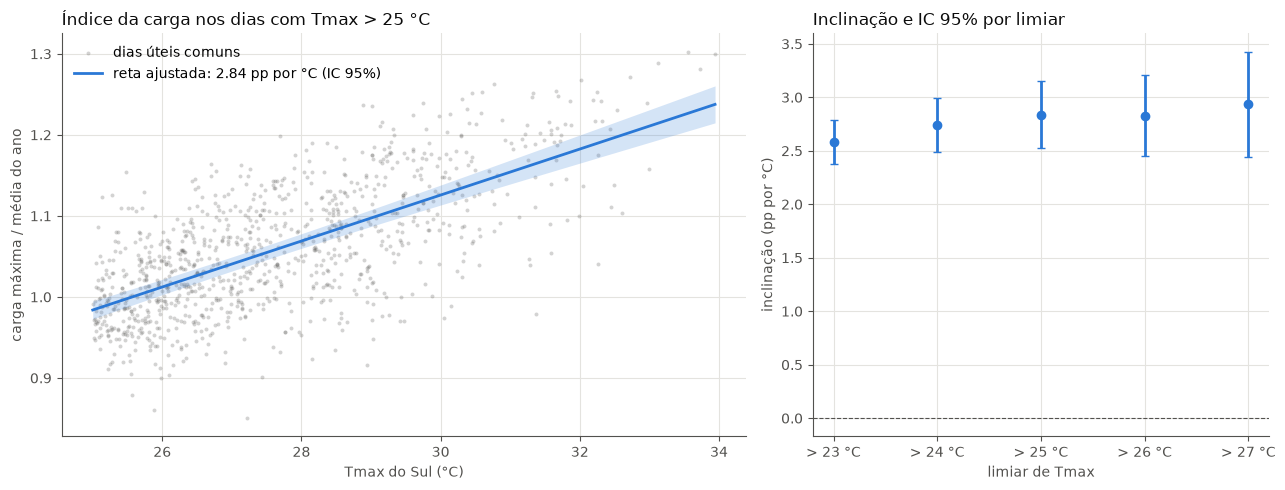

In [32]:
grade = pd.DataFrame({"tmax": np.linspace(amostra_h1["tmax"].min(), amostra_h1["tmax"].max(), 50)})
previsao = ajuste_h1.get_prediction(sm.add_constant(grade, has_constant="add")).summary_frame(alpha=0.05)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), width_ratios=[3, 2])
ax1.scatter(amostra_h1["tmax"], amostra_h1["indice"], s=8, color=TINTA_2, alpha=0.25, lw=0, label="dias úteis comuns")
ax1.fill_between(grade["tmax"], previsao["mean_ci_lower"], previsao["mean_ci_upper"], color=COR[0], alpha=0.2, lw=0)
ax1.plot(grade["tmax"], previsao["mean"], color=COR[0],
         label=f"reta ajustada: {100 * ajuste_h1.params['tmax']:.2f} pp por °C (IC 95%)")
ax1.set_xlabel("Tmax do Sul (°C)")
ax1.set_ylabel("carga máxima / média do ano")
ax1.set_title(f"Índice da carga nos dias com Tmax > {LIMIAR_CALOR:.0f} °C", loc="left", color=TINTA)
ax1.legend(loc="upper left")

lim = sensibilidade_h1.iloc[:len(LIMIARES_H1)]
ax2.errorbar(LIMIARES_H1, lim["inclinacao"], yerr=[lim["inclinacao"] - lim["ic95_inf"], lim["ic95_sup"] - lim["inclinacao"]],
             color=COR[0], marker="o", capsize=3, ls="none")
ax2.axhline(0, color=TINTA_2, lw=0.8, ls="--")
ax2.set_xticks(LIMIARES_H1, [f"> {l} °C" for l in LIMIARES_H1])
ax2.set_xlabel("limiar de Tmax")
ax2.set_ylabel("inclinação (pp por °C)")
ax2.set_title("Inclinação e IC 95% por limiar", loc="left", color=TINTA)
plt.tight_layout()

> **Interpretação**
>
> Nos 1.010 dias úteis comuns com Tmax acima de 25 °C (11 anos, 2015–2025), a carga máxima sobe 2,84 pp da média do ano a cada °C a mais de Tmax (IC 95% de 2,52 a 3,15 pp por °C). O p-valor unilateral é praticamente zero (3,9e-71), então H0 é rejeitada: os dados sustentam H1. Em MWmed, com efeito fixo de ano, a inclinação é de 455 MW por °C (IC 95% de 408 a 502). Esse valor é uma média entre os anos e fica um pouco abaixo dos cerca de 490 MW por °C da seção 9, que usam o nível de carga de 2025.
>
> O Durbin-Watson de 0,50 mostra que os resíduos de dias próximos são fortemente correlacionados: ondas de calor duram vários dias, e os dias de uma mesma onda não são observações independentes. Por isso os ICs usam erros-padrão de Newey-West, que ficam mais largos que os da regressão comum. Mesmo assim, o intervalo fica longe de zero. O R² de 0,46 indica que a Tmax explica cerca de metade da variação do índice nos dias quentes; o restante vem de outros fatores, o que combina com a dispersão crescente vista na seção 9.
>
> O resultado não depende do limiar de 25 °C. Entre 23 °C e 27 °C, a inclinação vai de 2,58 a 2,93 pp por °C, e todos os ICs se sobrepõem e excluem o zero. A inclinação cresce um pouco com o limiar porque os limiares mais baixos incluem o início da curva, onde a subida é mais lenta (1,27 pp na faixa de 22–24 °C). O efeito também aparece nos três regimes do ONS (2,94, 2,64 e 3,08 pp por °C), com ICs que se sobrepõem. O valor menor do regime 1 está dentro do IC dos outros e pode vir do efeito do índice em jan–abr/2023, descrito na seção 9.
>
> Para a previsão de D+1, isso significa que a temperatura é um preditor forte nos dias quentes, mas a Tmax observada em D+1 não pode ser usada como atributo, porque só é conhecida depois. Com uma inclinação de cerca de 2,8 pp por °C, um erro de 1 °C na temperatura usada no modelo vira um erro de quase 3% na carga máxima prevista. Os modelos terão de usar a Tmax de D ou previsões meteorológicas emitidas em D.

## 11. Teste de H3 – frio

**Hipótese:** a relação entre temperatura e carga máxima não é linear, mas em forma de U: dias muito frios também elevam a carga, por causa do aquecimento.

O teste previsto na proposta compara um ajuste linear com um quadrático e testa a significância do termo adicional. Esse teste sozinho não basta. Como a curva da seção 9 é muito assimétrica, o termo quadrático sairia significativo só por causa do ramo quente, mesmo que o frio não tivesse efeito nenhum. Por isso o teste é feito em duas partes:

1. **Curvatura (11.2):** `índice ~ Tmax` contra `índice ~ Tmax + Tmax²`. H0: coeficiente de Tmax² ≤ 0.
2. **Ramo frio (11.3):** só os dias com Tmax abaixo de `LIMIAR_FRIO`. H0: inclinação ≥ 0 (o frio não eleva a carga); H1: inclinação < 0.

A amostra é a mesma das seções 9 e 10 (`uteis_indice`: dias úteis comuns, índice da carga em relação à média do ano), e os erros-padrão são de Newey-West, como em H1.

### 11.1 Amostra

In [33]:
amostra_h3 = sql("""
SELECT u.data, u.ano, u.mes, u.regime_ons, u.tmax, d.tmin, u.indice
FROM uteis_indice u
JOIN diaria d USING (data)
ORDER BY u.data
""")

sql(f"""
SELECT CASE WHEN tmax < {LIMIAR_FRIO} THEN 'ramo frio (Tmax < {LIMIAR_FRIO:.0f} °C)' ELSE 'demais dias' END AS grupo,
       COUNT(*) AS n_dias,
       ROUND(MIN(tmax), 1) AS tmax_min,
       ROUND(MAX(tmax), 1) AS tmax_max,
       ROUND(AVG(indice), 4) AS indice_medio,
       list_sort(list(DISTINCT mes)) AS meses
FROM amostra_h3
GROUP BY grupo
ORDER BY grupo DESC
""")

,grupo,n_dias,tmax_min,tmax_max,indice_medio,meses
0,ramo frio (Tmax < 20 °C),565,10.4,20.0,0.956,"[3, 4, 5, 6, 7, 8, 9, 10, 11]"
1,demais dias,1949,20.0,33.9,1.010,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]"


### 11.2 Ajuste linear contra quadrático

In [34]:
def mqo_hac(y, X):
    """MQO com erros-padrão HAC (Newey-West), com as mesmas defasagens de H1."""
    return sm.OLS(y, sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})


t_c = (amostra_h3["tmax"] - CENTRO_QUAD).rename("tmax_c")
ajuste_lin = mqo_hac(amostra_h3["indice"], t_c.to_frame())
ajuste_quad = mqo_hac(amostra_h3["indice"], pd.DataFrame({"tmax_c": t_c, "tmax_c2": t_c ** 2}))

b1, b2 = ajuste_quad.params["tmax_c"], ajuste_quad.params["tmax_c2"]
ic_b2 = ajuste_quad.conf_int().loc["tmax_c2"]
resultado_quad = pd.DataFrame({
    "linear": {"n_dias": ajuste_lin.nobs, "r2": ajuste_lin.rsquared, "aic": ajuste_lin.aic},
    "quadrático": {"n_dias": ajuste_quad.nobs, "r2": ajuste_quad.rsquared, "aic": ajuste_quad.aic,
                   "coef_tmax2": b2, "ic95_inf": ic_b2.iloc[0], "ic95_sup": ic_b2.iloc[1],
                   "p_unilateral": stats.norm.sf(ajuste_quad.tvalues["tmax_c2"]),
                   "tmax_minimo": CENTRO_QUAD - b1 / (2 * b2)},
}).T
resultado_quad.style.format({"n_dias": "{:.0f}", "r2": "{:.3f}", "aic": "{:.0f}", "coef_tmax2": "{:.5f}",
                             "ic95_inf": "{:.5f}", "ic95_sup": "{:.5f}", "p_unilateral": "{:.1e}",
                             "tmax_minimo": "{:.1f}"}, na_rep="")

,n_dias,r2,aic,coef_tmax2,ic95_inf,ic95_sup,p_unilateral,tmax_minimo
linear,2514,0.413,-7231,,,,,
quadrático,2514,0.648,-8517,0.00161,0.00149,0.00173,7.8e-145,19.3


### 11.3 Inclinação do ramo frio

Três especificações, todas com os dias abaixo de `LIMIAR_FRIO`:
- **simples:** índice contra Tmax;
- **com efeito fixo de mês:** compara dias frios e menos frios do mesmo mês. Isso tira da inclinação o que é sazonal, mas não é temperatura, como os dias mais curtos do inverno (mais iluminação no pico das 18h, seção 6);
- **Tmin com efeito fixo de mês:** o aquecimento é mais usado nas horas frias da manhã e da noite, que a Tmin representa melhor que a Tmax.

In [35]:
def ramo_frio(dados, x="tmax", efeito_mes=False):
    """Inclinação do índice contra x (pp por °C) e teste unilateral de H0: inclinação >= 0."""
    X = dados[[x]]
    if efeito_mes:
        X = X.join(pd.get_dummies(dados["mes"], prefix="mes", drop_first=True, dtype=float))
    ajuste = mqo_hac(dados["indice"], X)
    ic = ajuste.conf_int().loc[x]
    return {
        "n_dias": int(ajuste.nobs),
        "inclinacao_pp": 100 * ajuste.params[x],
        "ic95_inf": 100 * ic.iloc[0],
        "ic95_sup": 100 * ic.iloc[1],
        "p_unilateral": stats.norm.cdf(ajuste.tvalues[x]),
        "r2": ajuste.rsquared,
    }


frio = amostra_h3[amostra_h3["tmax"] < LIMIAR_FRIO]
resultado_h3 = pd.DataFrame({
    "Tmax, simples": ramo_frio(frio),
    "Tmax, efeito fixo de mês": ramo_frio(frio, efeito_mes=True),
    "Tmin, efeito fixo de mês": ramo_frio(frio, x="tmin", efeito_mes=True),
}).T
FORMATO_H3 = {"n_dias": "{:.0f}", "inclinacao_pp": "{:.2f}", "ic95_inf": "{:.2f}", "ic95_sup": "{:.2f}",
              "p_unilateral": "{:.1e}", "r2": "{:.3f}"}
resultado_h3.style.format(FORMATO_H3)

,n_dias,inclinacao_pp,ic95_inf,ic95_sup,p_unilateral,r2
"Tmax, simples",565,-0.76,-0.96,-0.56,2.4e-14,0.195
"Tmax, efeito fixo de mês",565,-0.62,-0.80,-0.44,4.9e-12,0.281
"Tmin, efeito fixo de mês",565,-0.53,-0.67,-0.38,2.1e-12,0.310


### 11.4 Sensibilidade ao limiar e aos regimes do ONS

In [36]:
linhas = []
for limiar in LIMIARES_H3:
    dados = amostra_h3[amostra_h3["tmax"] < limiar]
    linhas.append({"recorte": f"Tmax < {limiar} °C", **ramo_frio(dados)})
    linhas.append({"recorte": f"Tmax < {limiar} °C, efeito fixo de mês", **ramo_frio(dados, efeito_mes=True)})
for r in range(3):
    dados = frio[frio["regime_ons"] == r]
    linhas.append({"recorte": f"Tmax < {LIMIAR_FRIO:.0f} °C, regime_ons = {r}", **ramo_frio(dados)})

sensibilidade_h3 = pd.DataFrame(linhas).set_index("recorte")
sensibilidade_h3.style.format(FORMATO_H3)

,n_dias,inclinacao_pp,ic95_inf,ic95_sup,p_unilateral,r2
recorte,,,,,,
Tmax < 18 °C,292,-1.01,-1.28,-0.74,8.6e-14,0.230
"Tmax < 18 °C, efeito fixo de mês",292,-0.89,-1.14,-0.63,3.3e-12,0.296
Tmax < 19 °C,420,-0.92,-1.14,-0.71,3.0e-17,0.245
"Tmax < 19 °C, efeito fixo de mês",420,-0.77,-0.97,-0.58,3.6e-15,0.320
Tmax < 20 °C,565,-0.76,-0.96,-0.56,2.4e-14,0.195
"Tmax < 20 °C, efeito fixo de mês",565,-0.62,-0.80,-0.44,4.9e-12,0.281
Tmax < 21 °C,696,-0.66,-0.83,-0.49,1.3e-14,0.183
"Tmax < 21 °C, efeito fixo de mês",696,-0.54,-0.70,-0.39,2.5e-12,0.272
Tmax < 22 °C,854,-0.50,-0.65,-0.34,1.4e-10,0.130


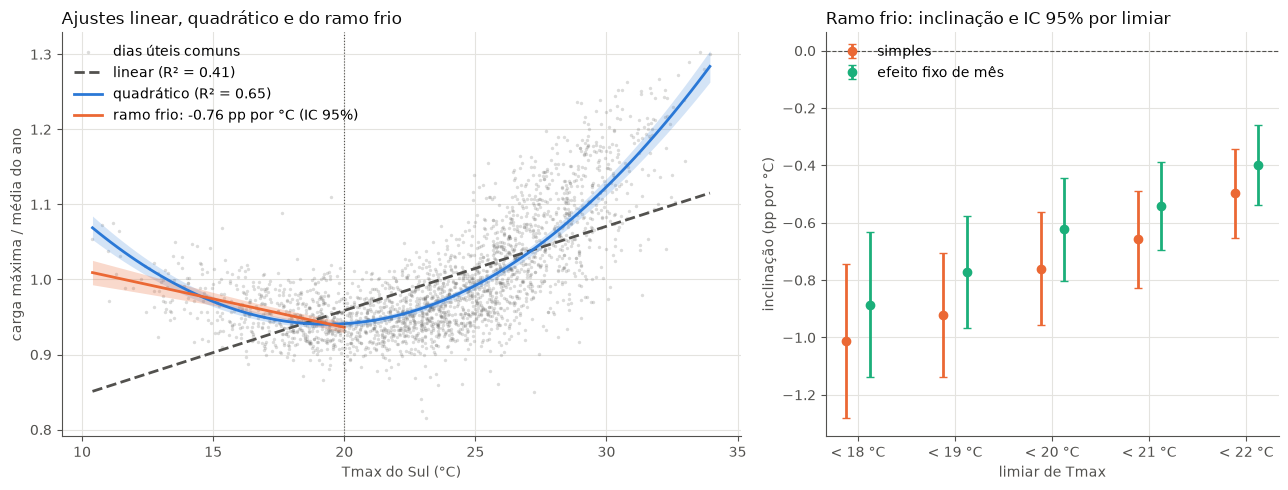

In [37]:
grade = pd.DataFrame({"tmax_c": np.linspace(amostra_h3["tmax"].min(), amostra_h3["tmax"].max(), 100) - CENTRO_QUAD})
grade["tmax_c2"] = grade["tmax_c"] ** 2
prev_quad = ajuste_quad.get_prediction(sm.add_constant(grade, has_constant="add")).summary_frame(alpha=0.05)
prev_lin = ajuste_lin.get_prediction(sm.add_constant(grade[["tmax_c"]], has_constant="add")).summary_frame(alpha=0.05)
x_grade = grade["tmax_c"] + CENTRO_QUAD

ajuste_frio = mqo_hac(frio["indice"], frio[["tmax"]])
grade_frio = pd.DataFrame({"tmax": np.linspace(frio["tmax"].min(), LIMIAR_FRIO, 50)})
prev_frio = ajuste_frio.get_prediction(sm.add_constant(grade_frio, has_constant="add")).summary_frame(alpha=0.05)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), width_ratios=[3, 2])
ax1.scatter(amostra_h3["tmax"], amostra_h3["indice"], s=6, color=TINTA_2, alpha=0.2, lw=0, label="dias úteis comuns")
ax1.plot(x_grade, prev_lin["mean"], color=TINTA_2, ls="--", label=f"linear (R² = {ajuste_lin.rsquared:.2f})")
ax1.fill_between(x_grade, prev_quad["mean_ci_lower"], prev_quad["mean_ci_upper"], color=COR[0], alpha=0.2, lw=0)
ax1.plot(x_grade, prev_quad["mean"], color=COR[0], label=f"quadrático (R² = {ajuste_quad.rsquared:.2f})")
ax1.fill_between(grade_frio["tmax"], prev_frio["mean_ci_lower"], prev_frio["mean_ci_upper"], color=COR[1], alpha=0.25, lw=0)
ax1.plot(grade_frio["tmax"], prev_frio["mean"], color=COR[1],
         label=f"ramo frio: {100 * ajuste_frio.params['tmax']:.2f} pp por °C (IC 95%)")
ax1.axvline(LIMIAR_FRIO, color=TINTA_2, lw=0.8, ls=":")
ax1.set_xlabel("Tmax do Sul (°C)")
ax1.set_ylabel("carga máxima / média do ano")
ax1.set_title("Ajustes linear, quadrático e do ramo frio", loc="left", color=TINTA)
ax1.legend(loc="upper left")

lim = sensibilidade_h3.loc[[f"Tmax < {l} °C" for l in LIMIARES_H3]]
lim_fe = sensibilidade_h3.loc[[f"Tmax < {l} °C, efeito fixo de mês" for l in LIMIARES_H3]]
for dados, cor, desloc, nome in [(lim, COR[1], -0.12, "simples"), (lim_fe, COR[2], 0.12, "efeito fixo de mês")]:
    ax2.errorbar(np.array(LIMIARES_H3) + desloc, dados["inclinacao_pp"],
                 yerr=[dados["inclinacao_pp"] - dados["ic95_inf"], dados["ic95_sup"] - dados["inclinacao_pp"]],
                 color=cor, marker="o", capsize=3, ls="none", label=nome)
ax2.axhline(0, color=TINTA_2, lw=0.8, ls="--")
ax2.set_xticks(LIMIARES_H3, [f"< {l} °C" for l in LIMIARES_H3])
ax2.set_xlabel("limiar de Tmax")
ax2.set_ylabel("inclinação (pp por °C)")
ax2.set_title("Ramo frio: inclinação e IC 95% por limiar", loc="left", color=TINTA)
ax2.legend(loc="upper left")
plt.tight_layout()

> **Interpretação**
>
> A relação entre temperatura e carga máxima não é linear. Nos 2.514 dias úteis comuns, o ajuste quadrático explica 65% da variação do índice, contra 41% do linear, e o AIC cai de −7.231 para −8.517. O coeficiente de Tmax² é positivo (0,0016, IC 95% de 0,0015 a 0,0017), com p-valor unilateral praticamente zero (7,8e-145), então H0 é rejeitada para a curvatura. O mínimo da parábola fica em 19,3 °C, dentro da faixa de 18–22 °C em que a seção 9 encontrou o vale.
>
> Esse resultado não basta para confirmar a parte "frio" de H3, e o gráfico mostra o motivo. A parábola é simétrica, e a curva real não é: o ajuste quadrático é puxado pelo ramo quente e põe o índice de um dia de 10 °C em 1,07, enquanto os dados ficam perto de 1,01. Por isso o ramo frio foi testado em separado.
>
> Nos 565 dias com Tmax abaixo de 20 °C, a carga máxima sobe 0,76 pp da média do ano a cada °C a menos de Tmax (IC 95% de 0,56 a 0,96 pp por °C; p unilateral de 2,4e-14). H0 é rejeitada: os dados sustentam H3, e dias mais frios elevam a carga. O efeito resiste aos controles. Com efeito fixo de mês, que compara dias frios e menos frios do mesmo mês e tira da conta os dias curtos do inverno, a inclinação fica em 0,62 pp por °C (IC de 0,44 a 0,80). Com a Tmin no lugar da Tmax, fica em 0,53 pp por °C (IC de 0,38 a 0,67). Os R² são baixos (0,20 a 0,31): no ramo frio a temperatura explica bem menos da variação do que no ramo quente (0,46 em H1).
>
> O resultado também não depende do limiar nem do regime do ONS. Entre 18 °C e 22 °C, todos os ICs excluem o zero, com e sem efeito fixo de mês. A inclinação fica mais forte nos limiares mais baixos (1,01 pp por °C abaixo de 18 °C, contra 0,50 abaixo de 22 °C), porque os limiares altos incluem o fundo plano do vale. O ramo frio aparece nos três regimes (0,61, 0,79 e 1,03 pp por °C), com ICs que se sobrepõem.
>
> O U é muito assimétrico. O ramo frio tem cerca de um quarto da inclinação do ramo quente (0,76 contra 2,84 pp por °C em H1). Além disso, o Sul tem poucos dias muito frios: só 77 dias úteis comuns ficaram abaixo de 15 °C de Tmax em 11 anos. Na prática, ir de 20 °C para 12 °C eleva a carga em cerca de 6 pp, enquanto ir de 25 °C para 33 °C a eleva em mais de 20 pp.
>
> Para a previsão de D+1:
> - um modelo linear na Tmax erra dos dois lados do U. A regressão linear da Etapa 4 precisa de atributos que deem a forma da curva, como graus-dia de resfriamento e de aquecimento (`cdd` e `hdd`, que já estão na base) ou a Tmax por partes. Os modelos de árvore e o TabPFN aprendem a não linearidade sozinhos;
> - o frio pesa mais no pico de inverno das 18h (seção 6), então a Tmin, ou a temperatura do fim da tarde, pode ajudar mais que a Tmax nesses meses;
> - como o ramo frio é fraco e tem poucos dias extremos, não se deve esperar grande ganho do clima no inverno. A maior parte do ganho do clima deve vir do verão.


## 12. Carga em dias de tempestade

**Pergunta:** dias de tempestade têm carga máxima diferente da de dias úteis comparáveis, com a mesma temperatura?

`tempestade` vem das estações do INMET (rajada ≥ 60 km/h ou chuva ≥ 30 mm/h em alguma das três capitais, seção 6 da Etapa 2). Não há uma hipótese de sentido definida antes: a tempestade pode reduzir a carga (desligamentos na rede, queda da temperatura depois da chuva), e o calor que costuma vir antes dela pode aumentá-la. Por isso os testes são bilaterais.

O desenho repete o de H2 (seção 8). Cada dia útil comum com tempestade é comparado com a média dos dias úteis comuns **sem tempestade medida** do mesmo dia da semana, mês, ano e regime do ONS. Os dias sem registro da estação (`tempestade` ausente) não entram nem como tempestade nem como controle. Como em H2, só entram dias com pelo menos `MIN_CONTROLES` controles.

### 12.1 Pareamento de cada dia de tempestade com dias comparáveis

In [38]:
con.sql("""
CREATE OR REPLACE VIEW tempestade_pares AS
WITH uteis AS (
    SELECT * FROM diaria_cal
    WHERE tipo_dia = 'útil comum' AND NOT dia_incompleto
),
tempestades AS (
    SELECT data, ano, mes, dia_semana, regime_ons, carga_max, tmax, rajada_max, chuva_max_hora,
           frac_pop_tempestade, tempestade_curitiba, tempestade_florianopolis, tempestade_porto_alegre
    FROM uteis
    WHERE tempestade
),
controles AS (
    SELECT ano, mes, dia_semana, regime_ons,
           COUNT(*) AS n_controles,
           AVG(carga_max) AS carga_controle,
           AVG(tmax) AS tmax_controle
    FROM uteis
    WHERE tempestade = FALSE          -- exclui os dias sem medição (NULL)
    GROUP BY ano, mes, dia_semana, regime_ons
)
SELECT t.*, c.n_controles, c.carga_controle, c.tmax_controle,
       100 * (t.carga_max / c.carga_controle - 1) AS diferenca_pct,
       t.tmax - c.tmax_controle AS diferenca_tmax
FROM tempestades t
LEFT JOIN controles c USING (ano, mes, dia_semana, regime_ons)
""")

sql(f"""
SELECT CASE WHEN mes IN {MESES_QUENTES} THEN 'out–mar' ELSE 'abr–set' END AS periodo,
       COUNT(*) AS n_tempestades_uteis,
       COUNT(*) FILTER (WHERE n_controles >= {MIN_CONTROLES}) AS n_pareados,
       ROUND(AVG(n_controles), 1) AS controles_por_dia,
       ROUND(AVG(diferenca_tmax), 2) AS diferenca_tmax_media,
       COUNT(*) FILTER (WHERE frac_pop_tempestade > 0.5) AS n_mais_de_metade_da_pop
FROM tempestade_pares
GROUP BY periodo
ORDER BY periodo DESC
""")

,periodo,n_tempestades_uteis,n_pareados,controles_por_dia,diferenca_tmax_media,n_mais_de_metade_da_pop
0,out–mar,65,63,2.7,2.12,3
1,abr–set,38,33,2.7,1.97,5


### 12.2 Diferença sem ajuste

In [39]:
pares_temp = sql(f"SELECT * FROM tempestade_pares WHERE n_controles >= {MIN_CONTROLES} ORDER BY data")


def teste_bilateral(diferencas):
    """Diferença média (%) com IC 95% (t) e testes bilaterais de H0: diferença = 0."""
    d = diferencas.dropna()
    ic = stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=stats.sem(d))
    return {
        "n": len(d),
        "diferenca_media_pct": d.mean(),
        "ic95_inf": ic[0],
        "ic95_sup": ic[1],
        "mediana_pct": d.median(),
        "frac_acima_controle": (d > 0).mean(),
        "p_t": stats.ttest_1samp(d, 0).pvalue,
        "p_wilcoxon": stats.wilcoxon(d).pvalue,
    }


pd.DataFrame({
    "carga (%)": teste_bilateral(pares_temp["diferenca_pct"]),
    "Tmax (°C)": teste_bilateral(pares_temp["diferenca_tmax"]),
}).T.style.format({"n": "{:.0f}", "diferenca_media_pct": "{:.2f}", "ic95_inf": "{:.2f}", "ic95_sup": "{:.2f}",
                   "mediana_pct": "{:.2f}", "frac_acima_controle": "{:.0%}", "p_t": "{:.1e}", "p_wilcoxon": "{:.1e}"})

,n,diferenca_media_pct,ic95_inf,ic95_sup,mediana_pct,frac_acima_controle,p_t,p_wilcoxon
carga (%),96,1.79,0.28,3.31,1.04,55%,2.1e-02,4.9e-02
Tmax (°C),96,2.03,1.43,2.62,2.27,75%,9.9e-10,1.8e-08


### 12.3 Diferença com a mesma Tmax

Regressão da diferença de carga contra a diferença de Tmax entre o dia de tempestade e os seus controles. O intercepto é a diferença estimada quando a tempestade e os controles têm a mesma Tmax. Erros-padrão HC3, como na 8.4. Os recortes verificam se o resultado depende da época do ano, da capital atingida ou do ano de 2020.

In [40]:
def ajuste_tempestade(dados):
    """Diferença de carga (%) com a mesma Tmax (intercepto) e efeito de cada °C a mais (inclinação)."""
    ajuste = sm.OLS(dados["diferenca_pct"], sm.add_constant(dados[["diferenca_tmax"]])).fit(cov_type="HC3")
    ic = ajuste.conf_int()
    return {
        "n": int(ajuste.nobs),
        "diferenca_mesma_tmax_pct": ajuste.params["const"],
        "ic95_inf": ic.loc["const", 0],
        "ic95_sup": ic.loc["const", 1],
        "p_bilateral": ajuste.pvalues["const"],
        "pp_por_grau": ajuste.params["diferenca_tmax"],
        "r2": ajuste.rsquared,
    }


quentes = pares_temp["mes"].isin(MESES_QUENTES)
recortes_temp = {
    "todos (teste principal)": pares_temp,
    "out–mar": pares_temp[quentes],
    "abr–set": pares_temp[~quentes],
    "sem 2020 (pandemia)": pares_temp[pares_temp["ano"] != 2020],
    "tempestade em Curitiba": pares_temp[pares_temp["tempestade_curitiba"] == True],
    "tempestade em Florianópolis": pares_temp[pares_temp["tempestade_florianopolis"] == True],
    "tempestade em Porto Alegre": pares_temp[pares_temp["tempestade_porto_alegre"] == True],
}
resultado_temp = pd.DataFrame({nome: ajuste_tempestade(d) for nome, d in recortes_temp.items()}).T
ajuste_temp = sm.OLS(pares_temp["diferenca_pct"], sm.add_constant(pares_temp[["diferenca_tmax"]])).fit(cov_type="HC3")
resultado_temp.style.format({"n": "{:.0f}", "diferenca_mesma_tmax_pct": "{:.2f}", "ic95_inf": "{:.2f}", "ic95_sup": "{:.2f}",
                             "p_bilateral": "{:.1e}", "pp_por_grau": "{:.2f}", "r2": "{:.2f}"})

,n,diferenca_mesma_tmax_pct,ic95_inf,ic95_sup,p_bilateral,pp_por_grau,r2
todos (teste principal),96,-1.62,-2.86,-0.39,9.9e-03,1.69,0.44
out–mar,63,-2.07,-3.57,-0.57,6.9e-03,2.29,0.57
abr–set,33,-2.13,-3.63,-0.63,5.3e-03,0.85,0.29
sem 2020 (pandemia),91,-1.51,-2.82,-0.20,2.4e-02,1.61,0.41
tempestade em Curitiba,43,-1.78,-3.77,0.21,7.9e-02,1.38,0.32
tempestade em Florianópolis,28,-1.52,-3.69,0.65,1.7e-01,1.87,0.43
tempestade em Porto Alegre,32,-2.70,-4.96,-0.45,1.9e-02,2.11,0.67


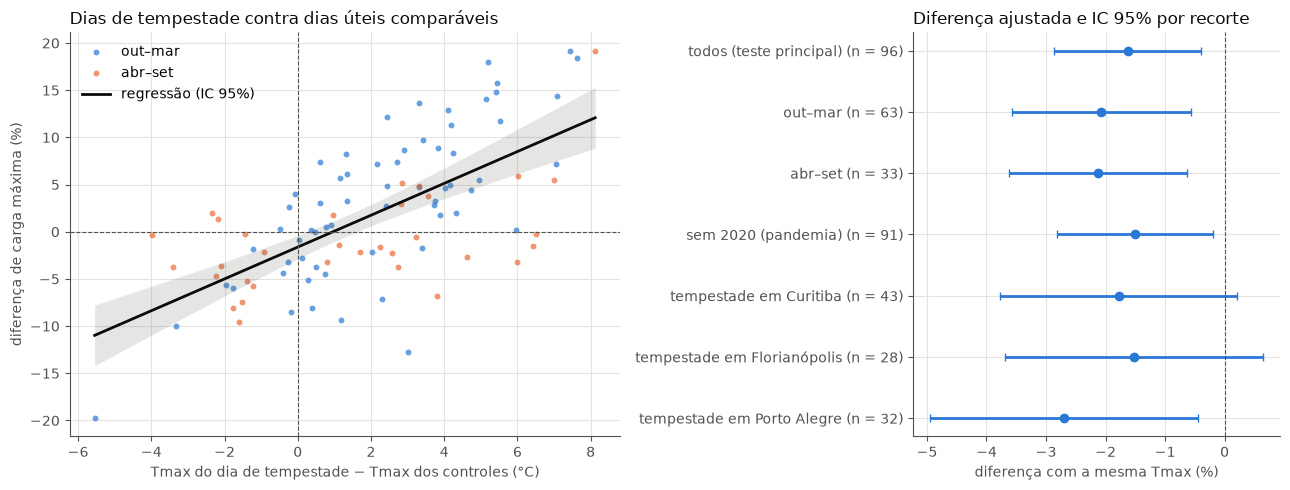

In [41]:
grade = pd.DataFrame({"diferenca_tmax": np.linspace(pares_temp["diferenca_tmax"].min(), pares_temp["diferenca_tmax"].max(), 50)})
prev = ajuste_temp.get_prediction(sm.add_constant(grade, has_constant="add")).summary_frame(alpha=0.05)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), width_ratios=[3, 2])
for cor, (nome, dados) in zip(COR, [("out–mar", pares_temp[quentes]), ("abr–set", pares_temp[~quentes])]):
    ax1.scatter(dados["diferenca_tmax"], dados["diferenca_pct"], s=18, color=cor, alpha=0.7, lw=0, label=nome)
ax1.fill_between(grade["diferenca_tmax"], prev["mean_ci_lower"], prev["mean_ci_upper"], color=TINTA_2, alpha=0.15, lw=0)
ax1.plot(grade["diferenca_tmax"], prev["mean"], color=TINTA, label="regressão (IC 95%)")
ax1.axhline(0, color=TINTA_2, lw=0.8, ls="--")
ax1.axvline(0, color=TINTA_2, lw=0.8, ls="--")
ax1.set_xlabel("Tmax do dia de tempestade − Tmax dos controles (°C)")
ax1.set_ylabel("diferença de carga máxima (%)")
ax1.set_title("Dias de tempestade contra dias úteis comparáveis", loc="left", color=TINTA)
ax1.legend(loc="upper left")

ordem = resultado_temp.index[::-1]
y = np.arange(len(ordem))
r = resultado_temp.loc[ordem]
ax2.errorbar(r["diferenca_mesma_tmax_pct"], y,
             xerr=[r["diferenca_mesma_tmax_pct"] - r["ic95_inf"], r["ic95_sup"] - r["diferenca_mesma_tmax_pct"]],
             color=COR[0], marker="o", capsize=3, ls="none")
ax2.axvline(0, color=TINTA_2, lw=0.8, ls="--")
ax2.set_yticks(y, [f"{nome} (n = {n})" for nome, n in zip(ordem, r["n"].astype(int))])
ax2.set_xlabel("diferença com a mesma Tmax (%)")
ax2.set_title("Diferença ajustada e IC 95% por recorte", loc="left", color=TINTA)
plt.tight_layout()

> **Interpretação**
>
> Entre 2015 e 2025 houve 103 dias úteis comuns com tempestade em alguma das três capitais, dois terços deles de outubro a março. Desses, 96 foram pareados, com 2,7 dias de controle em média. Sem ajuste, a carga máxima dos dias de tempestade ficou **1,8% acima** da dos controles (IC 95% de 0,3% a 3,3%; p de 0,02 no t e de 0,049 no Wilcoxon). Lido sozinho, esse número diria que a tempestade aumenta a carga. Mas os dias de tempestade foram, em média, 2,0 °C mais quentes que os controles, e 75% deles foram mais quentes. São tempestades de calor, que se formam depois de dias abafados.
>
> Com a mesma Tmax, o sinal se inverte. A regressão estima que um dia de tempestade tem carga **1,6% abaixo** da dos controles (IC 95% de −2,9% a −0,4%; p = 0,01). Cada °C a mais no dia de tempestade, em relação aos controles, soma 1,7 pp à diferença, um valor da mesma ordem do efeito do calor em H1. O calor que acompanha a tempestade esconde o efeito dela: é um caso de confundimento, e é por isso que a comparação precisa controlar a temperatura.
>
> O resultado se mantém nos recortes. Nas duas épocas do ano a diferença ajustada é de cerca de −2,1%, e sem 2020 fica em −1,5%. O valor do teste principal fica um pouco mais perto de zero do que os das duas épocas, porque o efeito de cada °C é bem maior em out–mar (2,3 pp) do que em abr–set (0,85 pp), e uma só inclinação mistura os dois. Separando por capital, as três estimativas são negativas (de −1,5% a −2,7%), mas só a de Porto Alegre tem IC que exclui o zero. As amostras por capital são pequenas (28 a 43 dias).
>
> O efeito é pequeno. A queda de 1,6% equivale a pouco menos de 1 °C de Tmax nos dias quentes e é cerca de um décimo da queda de um feriado (seção 8). Parte disso vem de as tempestades serem locais: em só 8 dos 103 dias a tempestade atingiu mais da metade da população do Sul (12.1), e uma tempestade em uma capital mexe pouco com a carga das três. Os dados não dizem qual é o mecanismo. A queda pode vir de desligamentos na rede de distribuição ou do resfriamento depois da chuva. Há também um cuidado na leitura: se a tempestade da tarde já derruba a Tmax do próprio dia, controlar pela Tmax tira da estimativa essa parte do efeito, e o −1,6% mede só o que sobra. Por fim, as lacunas da estação de Florianópolis em 2024 e 2025 reduzem a amostra dos anos mais recentes.
>
> Para a previsão de D+1:
> - a tempestade de D+1 não é conhecida na véspera, então o indicador observado não pode ser atributo. Ele só poderia entrar por meio de uma previsão meteorológica, e o ganho esperado é pequeno (cerca de 1,6% em menos de 10 dias úteis por ano);
> - o resultado reforça que o efeito do calor precisa vir de uma boa medida de temperatura: é a temperatura, e não a tempestade, que domina a carga desses dias;
> - na análise dos erros, os dias de tempestade são candidatos a erro para cima: com base no calor da véspera, o modelo deve prever carga alta, e a tempestade a reduz.


## 13. Dias que mais se desviaram da média móvel

**Pergunta:** quais dias mais se desviaram da média dos 28 dias anteriores, e o que eles tinham em comum (feriado, calor, tempestade, pandemia)?

Os outliers continuam na base (pedido do professor). Esta seção só os identifica e explica.

### 13.1 Desvio de cada dia em relação à média móvel (visão de apoio)

A referência de cada dia usa só dias anteriores a ele (`ROWS BETWEEN ... PRECEDING AND 1 PRECEDING`), então o próprio dia não contamina a média. Com `MM_MESMO_DIA_SEMANA = True`, a janela continua sendo de 28 dias, mas a média usa só os 4 dias da mesma semana dentro dela. Sem isso, todo domingo fica cerca de 15% abaixo da média e o top N se enche de fins de semana comuns. A anomalia de temperatura (`tmax_anomalia`) usa sempre os 28 dias corridos.

In [42]:
assert JANELA_MM % 7 == 0, "JANELA_MM precisa ser múltiplo de 7"
n_ref = JANELA_MM // 7 if MM_MESMO_DIA_SEMANA else JANELA_MM
particao = "PARTITION BY dia_semana" if MM_MESMO_DIA_SEMANA else ""

con.sql(f"""
CREATE OR REPLACE VIEW desvios_mm AS
WITH base AS (
    SELECT data, ano, dia_semana, tipo_dia, nome_feriado, regime_ons, pandemia, tempestade, tmax,
           CASE WHEN NOT dia_incompleto THEN carga_max END AS carga_max
    FROM diaria_cal
),
janela AS (
    SELECT *,
           AVG(carga_max) OVER w_ref AS carga_ref,
           COUNT(carga_max) OVER w_ref AS n_ref,
           COUNT(*) FILTER (WHERE tipo_dia IN ('feriado', 'recesso', 'ponte')) OVER w_ref AS n_especiais_na_ref,
           tmax - AVG(tmax) OVER w_clima AS tmax_anomalia,
           MIN(regime_ons) OVER w_clima <> regime_ons AS regime_mudou_na_janela
    FROM base
    WINDOW w_ref AS ({particao} ORDER BY data ROWS BETWEEN {n_ref} PRECEDING AND 1 PRECEDING),
           w_clima AS (ORDER BY data ROWS BETWEEN {JANELA_MM} PRECEDING AND 1 PRECEDING)
)
SELECT *,
       100 * (carga_max / carga_ref - 1) AS desvio_pct,
       CASE WHEN carga_max > carga_ref THEN 'acima' ELSE 'abaixo' END AS sentido
FROM janela
WHERE n_ref = {n_ref} AND carga_max IS NOT NULL
""")

sql("""
SELECT COUNT(*) AS n_dias,
       ROUND(STDDEV_SAMP(desvio_pct), 2) AS desvio_padrao_pct,
       ROUND(QUANTILE_CONT(desvio_pct, 0.01), 1) AS p01_pct,
       ROUND(QUANTILE_CONT(desvio_pct, 0.99), 1) AS p99_pct,
       COUNT(*) FILTER (WHERE ABS(desvio_pct) >= 20) AS n_desvio_20pct_ou_mais
FROM desvios_mm
""")

,n_dias,desvio_padrao_pct,p01_pct,p99_pct,n_desvio_20pct_ou_mais
0,3985,6.95,-18.4,20.1,73


### 13.2 Causa provável de cada desvio

As regras são separadas pelo sentido do desvio, para que uma causa de queda nunca explique um dia acima da referência (e vice-versa). Dentro de cada sentido, a ordem vai da causa mais certa para a mais estimada: calendário do próprio dia, evento datado (pandemia), medição (tempestade, temperatura) e, por fim, efeitos do próprio método (referência rebaixada por feriados ou recesso, troca de regime do ONS).

- **Referência rebaixada:** quando há feriado, recesso ou ponte entre os dias da referência, a média fica baixa e um dia normal parece alto. Isso é um artefato da média móvel, não um evento do dia.
- **Calor:** com `CALOR_RELATIVO = True`, conta a Tmax acima da média dos 28 dias anteriores (`tmax_anomalia`), que mede o que o dia teve de diferente das semanas anteriores. Com o limiar absoluto, quase todo dia útil de janeiro seria "calor".
- **Pandemia:** só na fase de adaptação (até `FIM_ADAPTACAO_PANDEMIA`). Depois disso a referência já está no patamar da pandemia.
- **Tempestade:** só explica queda (desligamentos). Nos dias acima da referência ela acompanha o calor e não é tratada como causa. `tempestade` NULL (sem dado do INMET) não conta.

In [43]:
def regra_causa(calor_relativo=CALOR_RELATIVO, min_especiais=MIN_ESPECIAIS_REF, combinado=ROTULO_COMBINADO):
    """CASE da causa provável. Ordem: calendário do dia > pandemia > tempestade > referência/calor > regime."""
    calor = f"tmax_anomalia >= {LIMIAR_ANOMALIA}" if calor_relativo else f"tmax >= {LIMIAR_CALOR}"
    ref = f"n_especiais_na_ref >= {min_especiais}"
    combinada = (f"WHEN sentido = 'acima' AND {ref} AND {calor} THEN 'calor + referência rebaixada'"
                 if combinado else "")
    return f"""
    CASE
        WHEN sentido = 'abaixo' AND tipo_dia IN ('feriado', 'recesso', 'ponte') THEN 'feriado ou recesso'
        WHEN sentido = 'abaixo' AND pandemia AND data < DATE '{FIM_ADAPTACAO_PANDEMIA}' THEN 'pandemia'
        WHEN sentido = 'abaixo' AND tempestade THEN 'tempestade'
        {combinada}
        WHEN sentido = 'acima' AND {ref} THEN 'referência rebaixada'
        WHEN sentido = 'acima' AND {calor} THEN 'calor'
        WHEN regime_mudou_na_janela THEN 'troca de regime do ONS'
        ELSE 'sem causa identificada'
    END"""


con.sql(f"""
CREATE OR REPLACE VIEW desvios_causa AS
SELECT *, {regra_causa()} AS causa
FROM desvios_mm
""")

sql("SELECT causa, sentido, COUNT(*) AS n_dias FROM desvios_causa GROUP BY causa, sentido ORDER BY n_dias DESC")

,causa,sentido,n_dias
0,sem causa identificada,abaixo,1641
1,sem causa identificada,acima,909
2,calor,acima,540
3,referência rebaixada,acima,386
4,feriado ou recesso,abaixo,217
5,calor + referência rebaixada,acima,163
6,tempestade,abaixo,58
7,pandemia,abaixo,32
8,troca de regime do ONS,abaixo,20
9,troca de regime do ONS,acima,19


### 13.3 Top N dias

In [44]:
top_desvios = sql(f"""
SELECT data,
       ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom'][dia_semana + 1] AS dia,
       tipo_dia, nome_feriado,
       ROUND(carga_max) AS carga_max_mw,
       ROUND(carga_ref) AS carga_ref_mw,
       ROUND(desvio_pct, 1) AS desvio_pct,
       ROUND(tmax, 1) AS tmax,
       ROUND(tmax_anomalia, 1) AS tmax_anomalia,
       tempestade, pandemia, n_especiais_na_ref, regime_mudou_na_janela,
       causa
FROM desvios_causa
ORDER BY ABS(desvio_pct) DESC
LIMIT {TOP_N_DESVIOS}
""")
top_desvios

,data,dia,tipo_dia,nome_feriado,carga_max_mw,carga_ref_mw,desvio_pct,tmax,tmax_anomalia,tempestade,pandemia,n_especiais_na_ref,regime_mudou_na_janela,causa
0,2016-03-25,sex,feriado,Sexta-feira Santa,9969.0,14801.0,-32.6,21.8,-3.9,False,False,0,False,feriado ou recesso
1,2017-12-25,seg,feriado,Natal,9883.0,14513.0,-31.9,21.9,-4.1,False,False,0,False,feriado ou recesso
2,2018-12-25,ter,feriado,Natal,10449.0,15246.0,-31.5,25.7,-1.4,False,False,0,False,feriado ou recesso
3,2020-01-15,qua,útil comum,NaN,17370.0,13284.0,30.8,30.3,1.4,False,False,2,False,referência rebaixada
4,2018-12-24,seg,recesso,NaN,10682.0,15106.0,-29.3,25.7,-1.3,False,False,0,False,feriado ou recesso
5,2022-01-21,sex,útil comum,NaN,18277.0,14180.0,28.9,31.7,3.3,False,False,2,False,calor + referência rebaixada
6,2016-01-15,sex,útil comum,NaN,15026.0,11665.0,28.8,27.2,0.4,False,False,2,False,referência rebaixada
7,2015-12-25,sex,feriado,Natal,9650.0,13545.0,-28.8,26.6,0.9,False,False,0,False,feriado ou recesso
8,2025-01-22,qua,útil comum,NaN,20402.0,15909.0,28.2,30.5,2.9,False,False,2,False,calor + referência rebaixada
9,2020-12-25,sex,feriado,Natal,11236.0,15598.0,-28.0,26.3,0.1,False,True,0,False,feriado ou recesso


### 13.4 O que os dias do top N têm em comum

In [45]:
sql(f"""
WITH top AS (
    SELECT * FROM desvios_causa ORDER BY ABS(desvio_pct) DESC LIMIT {TOP_N_DESVIOS}
)
SELECT causa, sentido,
       COUNT(*) AS n_dias,
       ROUND(AVG(desvio_pct), 1) AS desvio_medio_pct,
       ROUND(AVG(tmax), 1) AS tmax_media,
       ROUND(AVG(tmax_anomalia), 1) AS tmax_anomalia_media,
       COUNT(*) FILTER (WHERE tempestade) AS n_tempestade,
       COUNT(*) FILTER (WHERE tempestade IS NULL) AS n_sem_dado_inmet,
       list_sort(list(DISTINCT mes)) AS meses
FROM (SELECT *, month(data) AS mes FROM top)
GROUP BY causa, sentido
ORDER BY n_dias DESC
""")

,causa,sentido,n_dias,desvio_medio_pct,tmax_media,tmax_anomalia_media,n_tempestade,n_sem_dado_inmet,meses
0,feriado ou recesso,abaixo,16,-27.7,25.2,-1.2,0,1,"[1, 2, 3, 4, 12]"
1,referência rebaixada,acima,7,26.5,27.5,0.2,0,0,[1]
2,calor + referência rebaixada,acima,6,27.4,30.9,3.0,0,0,[1]
3,calor,acima,1,24.5,32.0,5.5,0,0,[12]


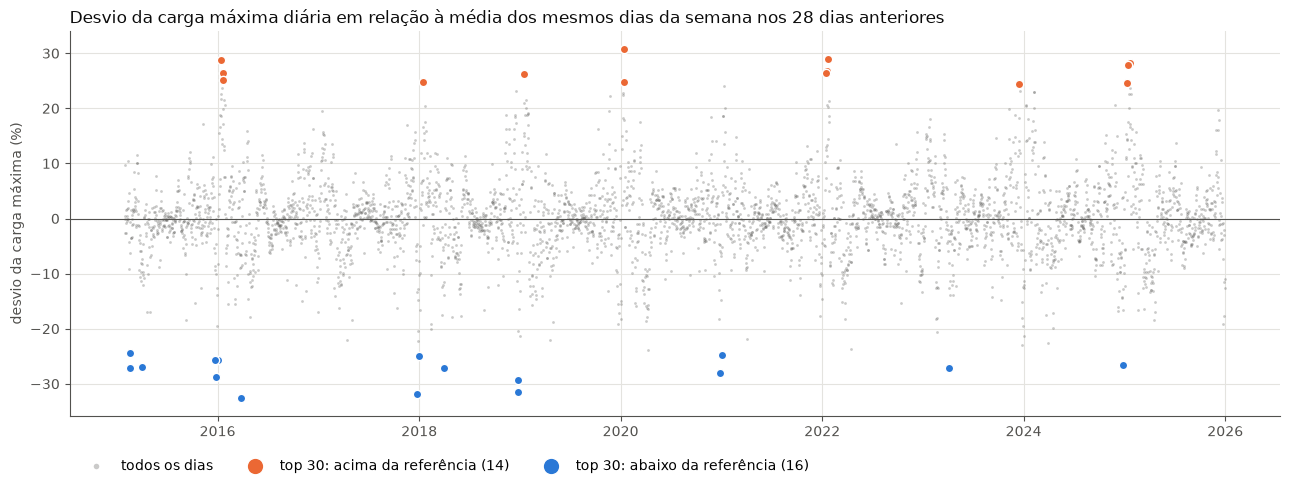

In [46]:
todos = sql("SELECT data, desvio_pct FROM desvios_mm ORDER BY data")

fig, ax = plt.subplots(figsize=(13, 5))
ax.scatter(todos["data"], todos["desvio_pct"], s=4, color=TINTA_2, alpha=0.3, lw=0, label="todos os dias")
for cor, sentido in [(COR[1], "acima"), (COR[0], "abaixo")]:
    t = top_desvios[top_desvios["desvio_pct"].gt(0) == (sentido == "acima")]
    ax.scatter(t["data"], t["desvio_pct"], s=36, color=cor, edgecolor="white", lw=1,
               label=f"top {TOP_N_DESVIOS}: {sentido} da referência ({len(t)})", zorder=3)
ax.axhline(0, color=TINTA_2, lw=0.8)
ref = f"mesmos dias da semana nos {JANELA_MM} dias anteriores" if MM_MESMO_DIA_SEMANA else f"{JANELA_MM} dias anteriores"
ax.set_ylabel("desvio da carga máxima (%)")
ax.set_title(f"Desvio da carga máxima diária em relação à média dos {ref}", loc="left", color=TINTA)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.08), ncols=3, markerscale=2)
plt.tight_layout()

### 13.5 Sensibilidade das regras

Contagem das causas no top N em cada combinação de critério de calor, mínimo de dias especiais na referência e rótulo combinado. A coluna marcada com `*` é a configuração usada acima.

In [47]:
combinacoes = [(rel, n, comb) for rel in (True, False) for n in (1, 2) for comb in (True, False)]
partes = []
for rel, n, comb in combinacoes:
    nome = f"{'relativo' if rel else 'absoluto'} | ref≥{n} | {'comb.' if comb else 'separado'}"
    if (rel, n, comb) == (CALOR_RELATIVO, MIN_ESPECIAIS_REF, ROTULO_COMBINADO):
        nome += " *"
    partes.append(sql(f"""
        SELECT {regra_causa(rel, n, comb)} AS causa, COUNT(*) AS n_dias, '{nome}' AS regra
        FROM (SELECT * FROM desvios_mm ORDER BY ABS(desvio_pct) DESC LIMIT {TOP_N_DESVIOS})
        GROUP BY ALL
    """))

sensibilidade_causa = (pd.concat(partes)
                       .pivot(index="causa", columns="regra", values="n_dias")
                       .fillna(0).astype(int))
sensibilidade_causa[[c for c in sensibilidade_causa.columns if c.endswith("*")] +
                    [c for c in sensibilidade_causa.columns if not c.endswith("*")]]

regra,relativo | ref≥1 | comb. *,absoluto | ref≥1 | comb.,absoluto | ref≥1 | separado,absoluto | ref≥2 | comb.,absoluto | ref≥2 | separado,relativo | ref≥1 | separado,relativo | ref≥2 | comb.,relativo | ref≥2 | separado
causa,,,,,,,,
calor,1,1,1,1,1,1,1,1
calor + referência rebaixada,6,13,0,13,0,0,6,0
feriado ou recesso,16,16,16,16,16,16,16,16
referência rebaixada,7,0,13,0,13,13,7,13


> **Interpretação**
>
> Dos 3.985 dias com referência completa, 98% ficam entre −18,4% e +20,1% da média dos mesmos dias da semana nas 4 semanas anteriores (desvio-padrão de 7,0%). Só 73 dias se afastam 20% ou mais. No top 30 há 16 dias abaixo da referência e 14 acima, e todos têm uma causa identificada pelas regras da 13.2.
>
> Os 16 maiores desvios para baixo são todos de calendário, de −24,5% a −32,6% (média de −27,7%):
> - Natal: 5 dias;
> - Sexta-feira Santa: 4 dias;
> - Confraternização Universal: 3 dias;
> - Carnaval de 2015: 2 dias;
> - 24/12 (recesso): 2 dias.
>
> A queda é o dobro da média dos feriados na seção 3.2 (−14%), porque aqui estão os feriados nacionais em que quase tudo fecha, e a comparação é com o mesmo dia da semana. Alguns desses dias foram frios (Sexta-feira Santa de 2023, 6,0 °C abaixo das semanas anteriores), mas a temperatura não explica a queda: o Natal de 2018, com temperatura normal, caiu 31,5%.
>
> Dos 14 maiores desvios para cima, 13 são dias de 8 a 22 de janeiro, e em todos eles 2 dos 4 dias da referência caíram no recesso de fim de ano. A referência fica rebaixada, e um dia útil normal de janeiro parece alto. Esses 13 dias se dividem em dois grupos de tamanho parecido:
> - 6 dias tiveram calor de verdade (Tmax 3,0 °C acima das semanas anteriores, em média);
> - 7 dias tiveram temperatura parecida com a das semanas anteriores (+0,2 °C) e ainda assim ficaram 26,5% acima da referência.
>
> Nesses 7 dias, o desvio vem do calendário da referência, não do próprio dia. O único desvio para cima fora de janeiro é o domingo 17/12/2023, com Tmax de 32,0 °C, 5,5 °C acima das semanas anteriores (+24,5%).
>
> Tempestade e pandemia não aparecem no top 30. Nenhum dos 30 dias teve tempestade registrada pelo INMET (um, 01/01/2021, não tem dado). Na base inteira, as regras marcam 58 dias abaixo da referência com tempestade, mas nenhum chega perto dos maiores desvios. A pandemia baixou a carga de forma gradual em março e abril de 2020, e a referência de 4 semanas foi acompanhando a queda. Por isso os 32 dias da fase de adaptação têm desvios moderados. A pandemia mudou o patamar da carga, mas não criou dias isolados fora da curva.
>
> A classificação não depende do ajuste fino das regras (13.5): com 1 ou 2 dias especiais na referência, o top 30 fica igual, e nenhuma combinação deixa dia sem causa. A escolha que muda o resultado é o critério de calor. Com o limiar absoluto de 25 °C, os 13 dias de janeiro viram "calor", porque quase todo dia de janeiro passa de 25 °C, e os 7 dias de temperatura normal ficam escondidos.
>
> Os outliers continuam na base. Para a previsão de D+1:
> - os maiores erros para baixo devem vir dos grandes feriados nacionais, e por isso vale distinguir o tipo de feriado (por exemplo, `nome_feriado`) em vez de usar só uma marcação binária;
> - atributos baseados nas semanas anteriores, como médias móveis ou lags de 7 e 28 dias, ficam rebaixados nas duas semanas depois do recesso. O modelo precisa saber que a referência inclui o recesso; caso contrário, vai subestimar a carga em meados de janeiro, justamente no início do verão.

## 14. Principais descobertas

### 14.1 Hipóteses

| Hipótese | Teste | Resultado | Conclusão |
|---|---|---|---|
| **H1 – calor** (seção 10) | MQO do índice contra a Tmax nos dias úteis comuns com Tmax > 25 °C, erros de Newey-West | +2,84 pp por °C (IC 95% de 2,52 a 3,15; p ≈ 4e-71); 455 MW por °C com efeito fixo de ano; vale para limiares de 23 a 27 °C e nos três regimes | sustentada |
| **H2 – feriados** (seção 8) | Pareamento com dias úteis do mesmo dia da semana, mês, ano e regime; t e Wilcoxon unilaterais | −14,7% (IC de −16,3% a −13,0%); 97% dos feriados abaixo dos controles; −15,0% com a mesma Tmax | sustentada |
| **H3 – frio** (seção 11) | Linear contra quadrático; inclinação do ramo frio (Tmax < 20 °C) com e sem efeito fixo de mês | Tmax² significativo (p ≈ 8e-145), mínimo em 19,3 °C; ramo frio de −0,76 pp por °C (IC de −0,96 a −0,56), −0,62 com efeito fixo de mês | sustentada, com efeito cerca de 4 vezes menor que o do calor |

### 14.2 Outras descobertas

1. **Tendência e regimes do ONS (seções 3 e 4).** A carga máxima média cresceu 33% entre 2015 e 2025 (de 12,6 para 16,8 GW). Os maiores saltos coincidem com as trocas de metodologia do ONS (mar/2021 e abr/2023), e a carga em MW não é comparável entre regimes.
2. **Sazonalidade (seção 5).** De dezembro a março a carga fica acima da média do ano, com o pico em fevereiro (cerca de 9% acima). De abril a outubro fica de 2% a 5% abaixo. O desenho acompanha a Tmax (correlação de 0,84 entre os 12 meses), com um pequeno aumento em julho.
3. **Hora do pico (seção 6).** O pico é às 14h no verão e às 18h no inverno. Entre 2021 e 2023 o pico de verão foi para o fim da tarde e depois voltou. A mudança coincide com o período em que a geração distribuída solar não era somada à carga, o que mostra que o regime muda o formato da curva e não só o nível.
4. **Granularidade (seção 7).** 63% da variação diária acontece dentro da semana, e o pico da semana fica 7,4% acima da média semanal. A correlação com a Tmax sobe ao agregar porque o calendário deixa de pesar, e não porque o clima explique mais. A escolha da granularidade diária se confirma.
5. **Calendário (seções 3 e 8).** Fim de semana −15%, feriados −14%, pontes −10% e recesso −9% em relação ao dia útil comum do mesmo ano. Comparados com dias úteis do mesmo dia da semana e mês, os grandes feriados (Confraternização Universal, Natal e Sexta-feira Santa) caem de 21% a 30%. O efeito dos feriados enfraqueceu ao longo do tempo (0,78 pp por ano), e com a mesma Tmax é de −11% em 2025.
6. **Tempestades (seção 12).** Sem ajuste, os dias de tempestade parecem ter carga 1,8% maior, mas foram 2 °C mais quentes que os controles. Com a mesma Tmax, a carga fica 1,6% menor (IC de −2,9% a −0,4%). O efeito é pequeno, e a comparação sem controle da temperatura levaria à conclusão errada.
7. **Eventos excepcionais (seção 13).** 98% dos dias ficam entre −18% e +20% da média das 4 semanas anteriores. Os maiores desvios para baixo são grandes feriados. Os maiores para cima são dias de janeiro cuja referência foi rebaixada pelo recesso. A pandemia baixou o patamar da carga em 2020, mas não criou dias isolados fora da curva.

### 14.3 Como isso orienta a modelagem

- **Nível e tendência:** lags e médias móveis da carga acompanham o crescimento, e `regime_ons` precisa entrar como atributo (ou o treino precisa considerar as trocas de regime).
- **Calendário:** atributos para fim de semana, feriado, tipo de feriado, ponte e recesso, e uma marcação para quando a janela das médias móveis inclui o recesso.
- **Clima:** a relação em U pede atributos como `cdd` e `hdd` nos modelos lineares. Os modelos de árvore aprendem a forma sozinhos. Só pode ser usado o clima observado até o dia D, e o maior ganho deve vir do verão, onde a inclinação é maior.
- **Tempestades:** não entram como atributo, porque a tempestade de D+1 não é conhecida na véspera e o efeito é pequeno.
- **Onde esperar mais erros:** grandes feriados, as duas semanas depois do recesso, dias de calor extremo, Carnaval quente e dias de tempestade.